---
title: "Alpha Diversity - Sample-level statistical modeling"
date: last-modified
date-format: "YYYY-MM-DD HH:mm:ss"
format:
  html:
    toc: true
    toc-depth: 5
    toc-location: left
    embed-resources: true
    page-layout: full
    fig-width: 12
    fig-height: 8
    fig-responsive: true
execute:
  echo: false
---
<style>
  .cell-output-display img {
    width: 100% !important;
    max-width: 900px !important;
    height: auto !important;
  }
</style>
***

Sample-level generalized linear modeling (GLM) provides a framework for evaluating how species richness varies among individual biological samples and whether those differences are associated with measured environmental or experimental factors. 

Unlike assemblage-level diversity analyses, which summarize diversity across pooled groups such as transects or substrate categories, sample-level GLMs treat each sampling unit as an observation. This approach allows variation in richness among samples to be modeled directly while accounting for multiple explanatory variables simultaneously.

In ecological studies, GLMs are commonly used when the response variable does not meet the assumptions of ordinary linear regression. Species richness is a count variable consisting of non-negative integers, making count-based distributions such as the Poisson or negative binomial appropriate candidates. 

Within this framework, the model can estimate how expected species richness changes in relation to predictors such as habitat, treatment, substrate type, ~~decay stage~~, or other environmental characteristics. More generally, sample-level GLMs can address questions such as whether richness differs among groups, whether observed differences persist after accounting for potentially confounding variables, and whether the relationship between a predictor and richness depends on another ecological factor.

For the Oulanka MycoPins study, sample-level GLM analysis complements the assemblage-level alpha-diversity analyses based on observed richness, Hill numbers, rarefaction and extrapolation, sample completeness, and coverage-standardized diversity. Whereas those analyses describe and compare overall diversity patterns among Transects A, B, and C and among wood substrates, the sample-level GLM evaluates whether individual deadwood samples differ systematically in the number of saproxylic fungal species they support. 

In particular, the analysis can test whether samples from Transect A differ in expected species richness from samples in Transect B after accounting for substrate characteristics such as wood type, wood texture, ~~decay class~~, or other measured covariates.

This analysis can therefore address several questions relevant to the study: 
* **Do individual samples in Transect A support greater fungal species richness than samples in Transect B?**
* **Does an A–B richness difference remain after accounting for differences in wood substrate or other sample characteristics?**
* **Which measured environmental or substrate variables are associated with sample-level richness?**
* **Does the relationship between transect and richness vary among wood types?**

Model-based estimates can also provide adjusted mean richness and confidence intervals for comparisons among groups.

Because Transects A and B represent different reindeer-access conditions, the A–B comparison may also provide evidence of an association between reindeer access and fungal richness. However, if each access condition is represented by only one transect, reindeer access is confounded with other environmental differences between those transects. 

Consequently, the sample-level GLM can test for a statistically supported difference in richness between Transects A and B, but it cannot by itself establish that reindeer access caused that difference. The analysis should therefore be interpreted as an inferential assessment of sample-level richness patterns and their associations with measured predictors rather than as a definitive test of a causal reindeer-access effect.

## 1. Observed sample-level richness

In [1]:
# Load shared R functions for the Oulanka datasets.
source("../src/oulanka.R")
source("../src/make_plots.R")

In [2]:
# Load genus-level saproxylic community data
saproxylic_community_df <- get_saproxylic_community_data(genus=TRUE)
# Load environment data
environment_df <- get_environment_data()

In [3]:
# Create the richness table. Restrict the analysis to Transect A and B
richness_df <- environment_df %>%
    select(
        Sample.Number,
        Transect,
        Wood.Type,
        Wood.Texture
    ) %>%
    mutate(
        Transect = factor(Transect, levels = c("A", "B")),
        Wood.Type = factor(Wood.Type),
        Wood.Texture = factor(Wood.Texture),
        Richness = specnumber(saproxylic_community_df)
    ) %>%
    filter(Transect %in% c("A", "B"))

### 1.1. Snapshot of the sample-level richness table

In [4]:
head(richness_df)

Sample.Number,Transect,Wood.Type,Wood.Texture,Richness
<chr>,<fct>,<fct>,<fct>,<int>
018561A,A,Pine,Softwood,1
018561C,A,Birch,Hardwood,5
018561E,A,Spruce,Softwood,2
018562C,A,Birch,Hardwood,1
018562E,A,Spruce,Softwood,1
018579B,A,Pine,Softwood,3


### 1.2. Summary statistics

#### Table 1: Summary statistics for sample-level saproxylic fungal species richness by transect.

In [5]:
summary_df <- richness_df %>%
    group_by(Transect) %>%
    summarise(
        n = n(),
        mean_richness = mean(Richness),
        sd_richness = sd(Richness),
        median_richness = median(Richness),
        min_richness = min(Richness),
        max_richness = max(Richness)
    ) 

In [6]:
caption_text <- paste0(
    "Table 1. Summary statistics for sample-level saproxylic fungal species richness by transect. ",
    "Values show the number of samples (n), mean species richness, standard deviation (SD), ",
    "median, minimum, and maximum richness observed within each transect."
)

table1 <- summary_df %>%
    gt() %>% 
    cols_label(
        Transect = md("**Transect**"),
        n = md("**Sample size (n)**"),
        mean_richness = md("**Mean richness**"),
        sd_richness = md("**SD**"),
        median_richness = md("**Median richness**"),
        min_richness = md("**Min richness**"),
        max_richness = md("**Max richness**"),
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    fmt_number(
        columns = c(3, 4),
        decimals = 2
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [7]:
table1 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 1. Summary statistics for sample-level saproxylic fungal species richness by transect. Values show the number of samples (n), mean species richness, standard deviation (SD), median, minimum, and maximum richness observed within each transect. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="n" align="center" bgcolor="#FFFFFF" valign="bottom"> Sample size (n) 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="mean_richness" align="center" bgcolor="#FFFFFF" valign="bottom"> Mean richness 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="sd_richness" align="center" bgcolor="#FFFFFF" valign="bottom"> SD 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D

### 1.3. Observed richness

#### Figure 1: Observed sample-Level fungal richness across transects

In [8]:
title_text = "Sample-Level fungal richness across transects"
subtitle_text = "Observed species richness among individual samples in Transects A, B, and C"
caption_text = paste0(
    "Figure 1. Observed sample-level fungal species richness across Transects A, B, and C. ",
    "Each point represents the number of fungal species observed in an individual sample. ",
    "Points are horizontally jittered within each transect to improve visualization of ",
    "overlapping observations and illustrate the distribution and variability of richness among samples."
)

figure1 <- ggplot() +
    geom_jitter(
        data = richness_df,
        aes(
            x = Transect,
            y = Richness
        ),
        width = 0.12,
        alpha = 0.35,
        size = 1.8
    ) +
    labs(
        title = title_text,
        subtitle = subtitle_text,
        caption = caption_text,
        x = "Transect",
        y = "Species richness"
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

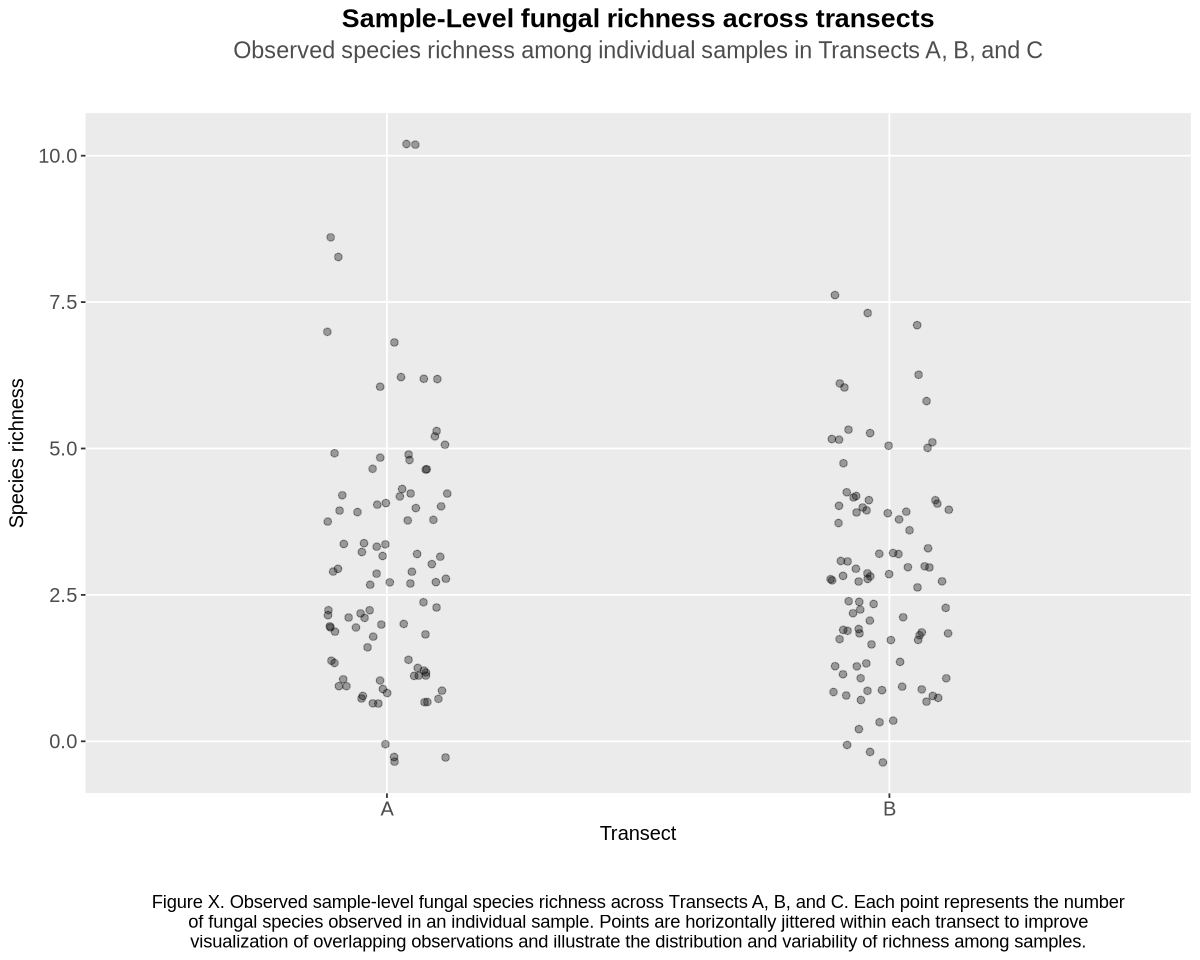

In [9]:
options(repr.plot.width = 10, repr.plot.height = 8)
figure1

## 2. Richness ~ Transect

### 2.1. Poisson model

In [10]:
model_poisson <- glm(
    Richness ~ Transect,
    family = poisson(link = "log"),
    data = richness_df
)

#### Model performance summary

In [11]:
summary(model_poisson)


Call:
glm(formula = Richness ~ Transect, family = poisson(link = "log"), 
    data = richness_df)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept)  1.11241    0.05852  19.009   <2e-16 ***
TransectB   -0.06528    0.08484  -0.769    0.442    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 247.85  on 188  degrees of freedom
Residual deviance: 247.26  on 187  degrees of freedom
AIC: 764.4

Number of Fisher Scoring iterations: 5


#### Check for overdispersion

In [12]:
check_overdispersion(model_poisson)

Overdispersion detected.



# Overdispersion test

       dispersion ratio =   1.274
  Pearson's Chi-Squared = 238.226
                p-value =   0.007


Assessment of the Poisson GLM indicated significant overdispersion (dispersion ratio = 1.274, Pearson's χ² = 238.226, p = 0.007), with **the residual variance approximately 27% greater than expected under the Poisson distribution**.

#### Check for goodness-of-fit

#### Figure 2: DHARMa simulated residual diagnostics

In [13]:
result <- simulateResiduals(
    fittedModel = model_poisson,
    n = 1000
)

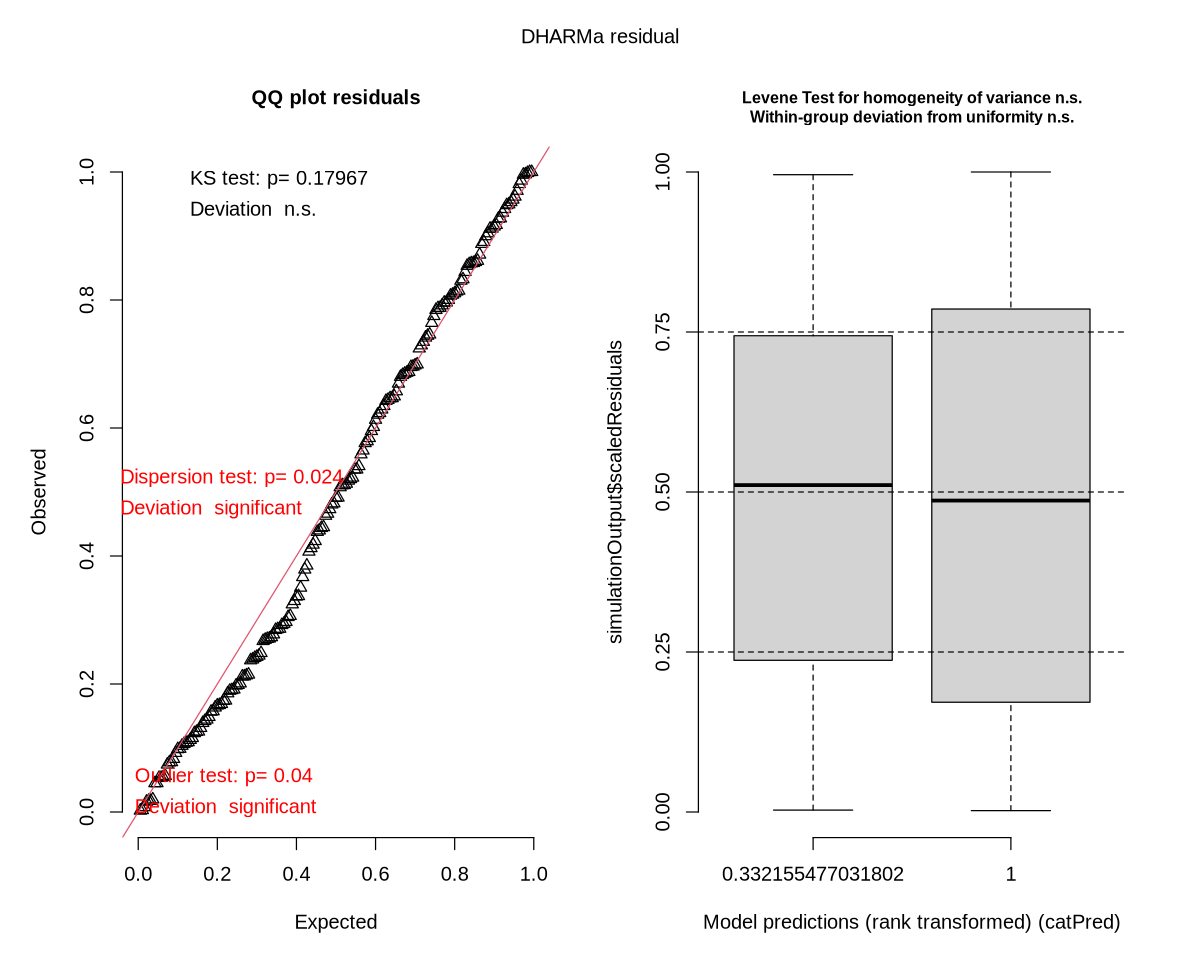

In [14]:
plot(result)

#### Figure 3: DHARMa disperson test result


	DHARMa nonparametric dispersion test via sd of residuals fitted vs.
	simulated

data:  simulationOutput
dispersion = 1.271, p-value = 0.024
alternative hypothesis: two.sided


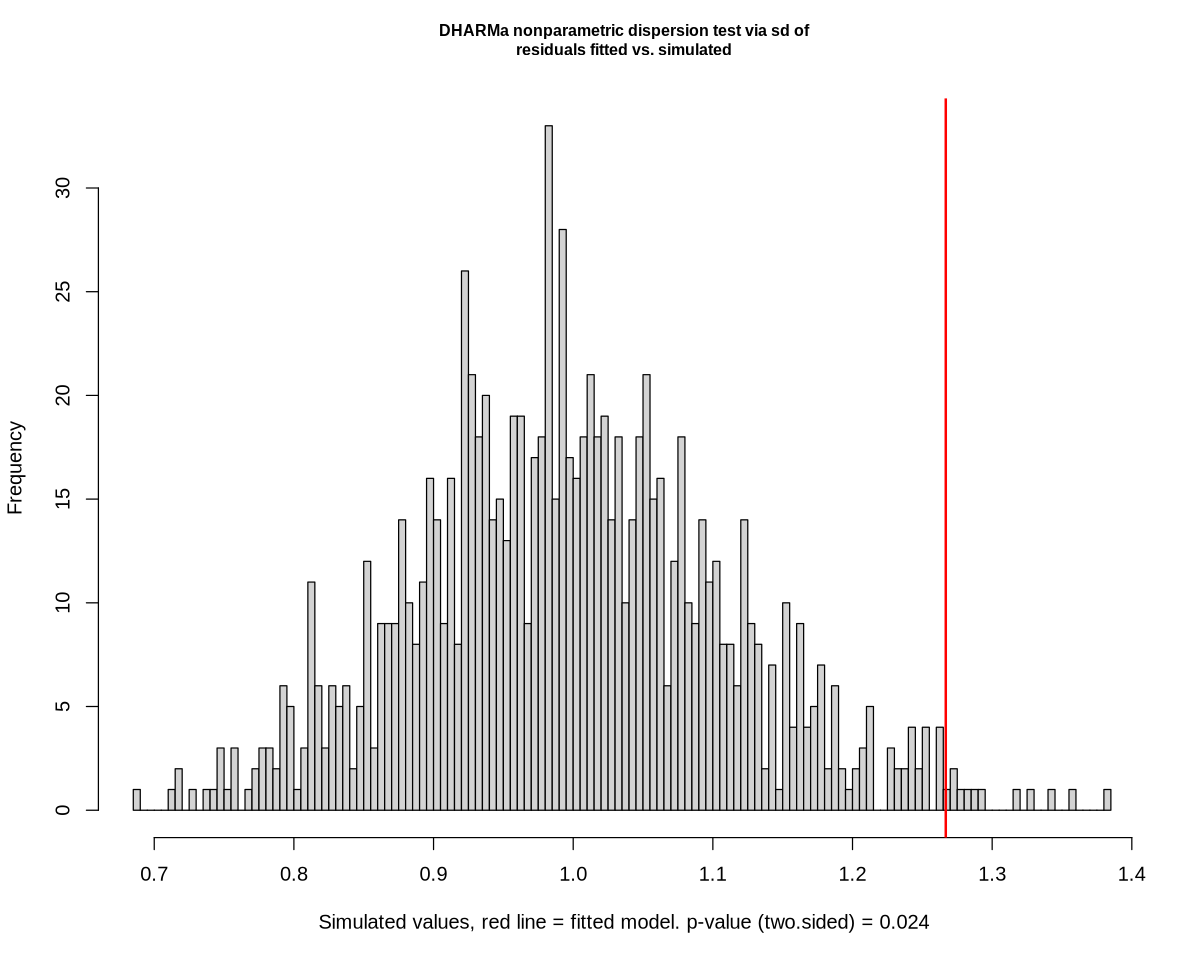

In [15]:
testDispersion(result)

#### Figure 4: DHARMa zero-inflation test result


	DHARMa zero-inflation test via comparison to expected zeros with
	simulation under H0 = fitted model

data:  simulationOutput
ratioObsSim = 0.9996, p-value = 1
alternative hypothesis: two.sided


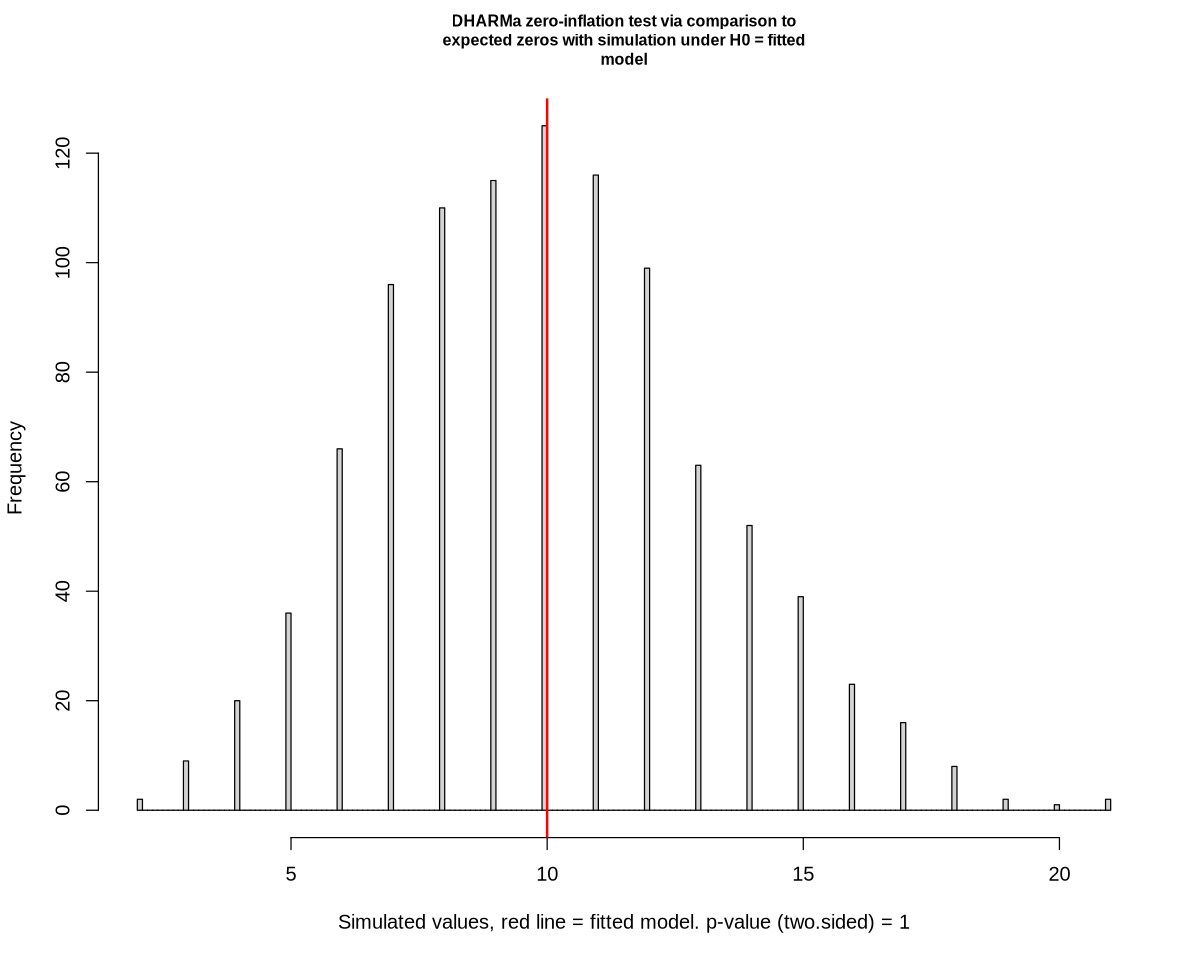

In [16]:
testZeroInflation(result)

### 2.2. Overdispersion detected. Use Negative-binomial model.

In [17]:
model_negative_binomial <- glmmTMB(
    Richness ~
        Transect,
    family = nbinom2(link = "log"),
    data = richness_df
)

#### Model performance summary

In [18]:
summary(model_negative_binomial)

 Family: nbinom2  ( log )
Formula:          Richness ~ Transect
Data: richness_df

      AIC       BIC    logLik -2*log(L)  df.resid 
    761.1     770.8    -377.6     755.1       186 


Dispersion parameter for nbinom2 family (): 11.7 

Conditional model:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept)  1.11241    0.06567  16.939   <2e-16 ***
TransectB   -0.06528    0.09489  -0.688    0.491    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

#### Check for overdispersion

In [19]:
check_overdispersion(model_negative_binomial)

No overdispersion detected.



# Overdispersion test (using simulated residuals)

 dispersion ratio = 1.021
          p-value = 0.832


No significant overdispersion was detected (dispersion ratio = 1.021, p = 0.856). **The dispersion ratio was close to 1 (at 1.02), indicating that the variance in sample-level species richness was adequately represented by the fitted model.**

#### Check for goodness-of-fit

In [20]:
result <- simulateResiduals(
    fittedModel = model_negative_binomial,
    n = 1000
)

#### Figure 5: DHARMa simulated residual diagnostics

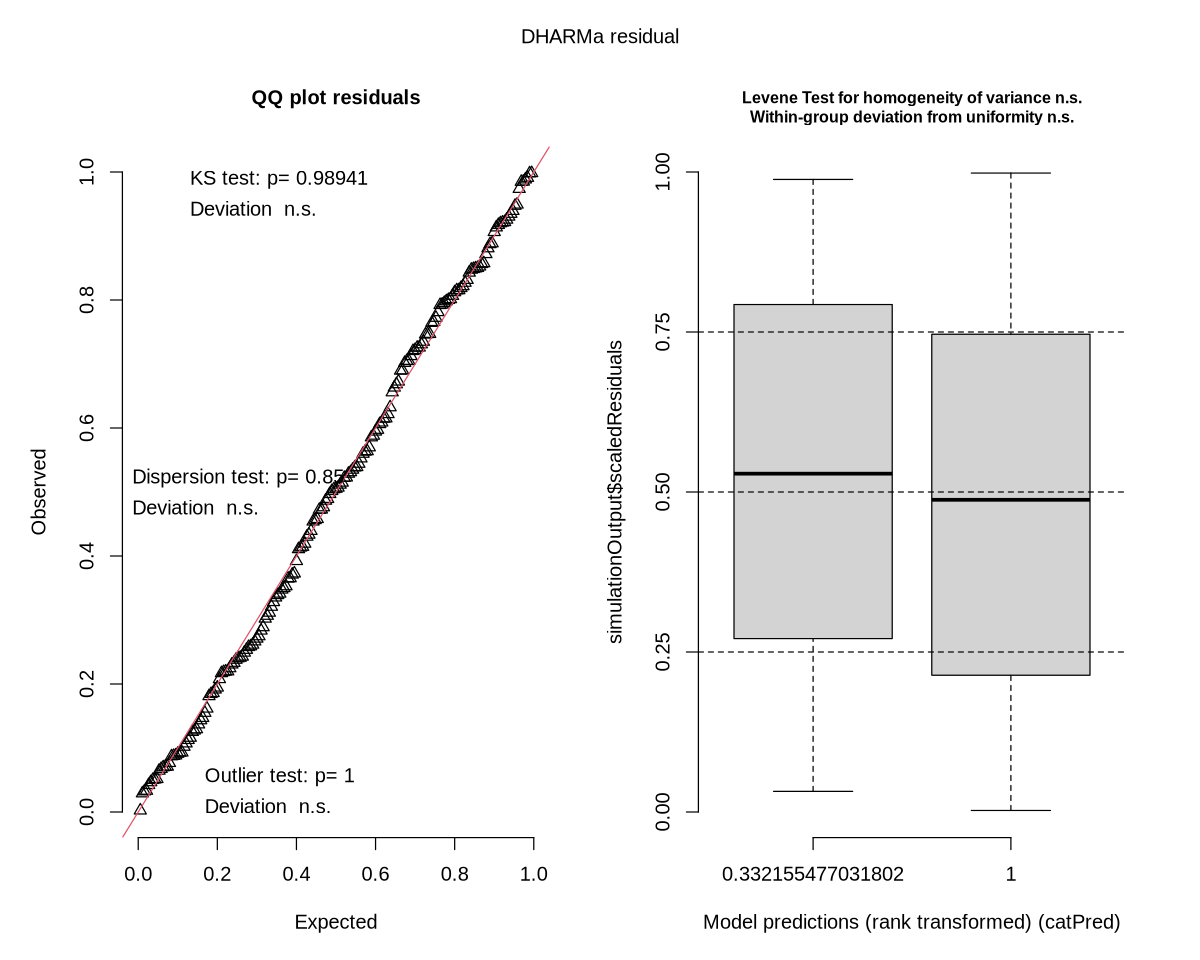

In [21]:
plot(result)

#### Figure 6: DHARMa disperson test result


	DHARMa nonparametric dispersion test via sd of residuals fitted vs.
	simulated

data:  simulationOutput
dispersion = 1.0147, p-value = 0.85
alternative hypothesis: two.sided


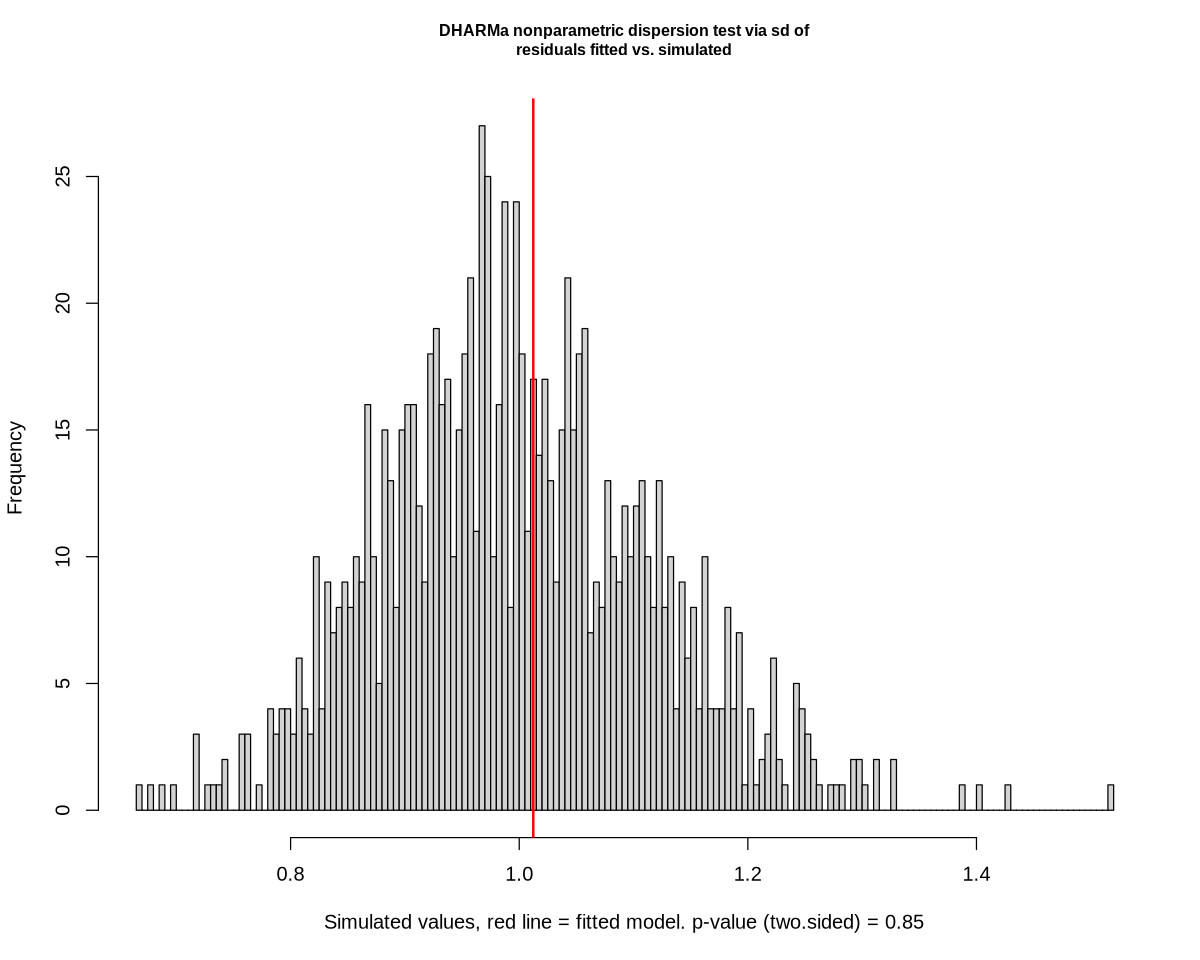

In [22]:
testDispersion(result)

#### Figure 7: DHARMa zero-inflation test result


	DHARMa zero-inflation test via comparison to expected zeros with
	simulation under H0 = fitted model

data:  simulationOutput
ratioObsSim = 0.71803, p-value = 0.328
alternative hypothesis: two.sided


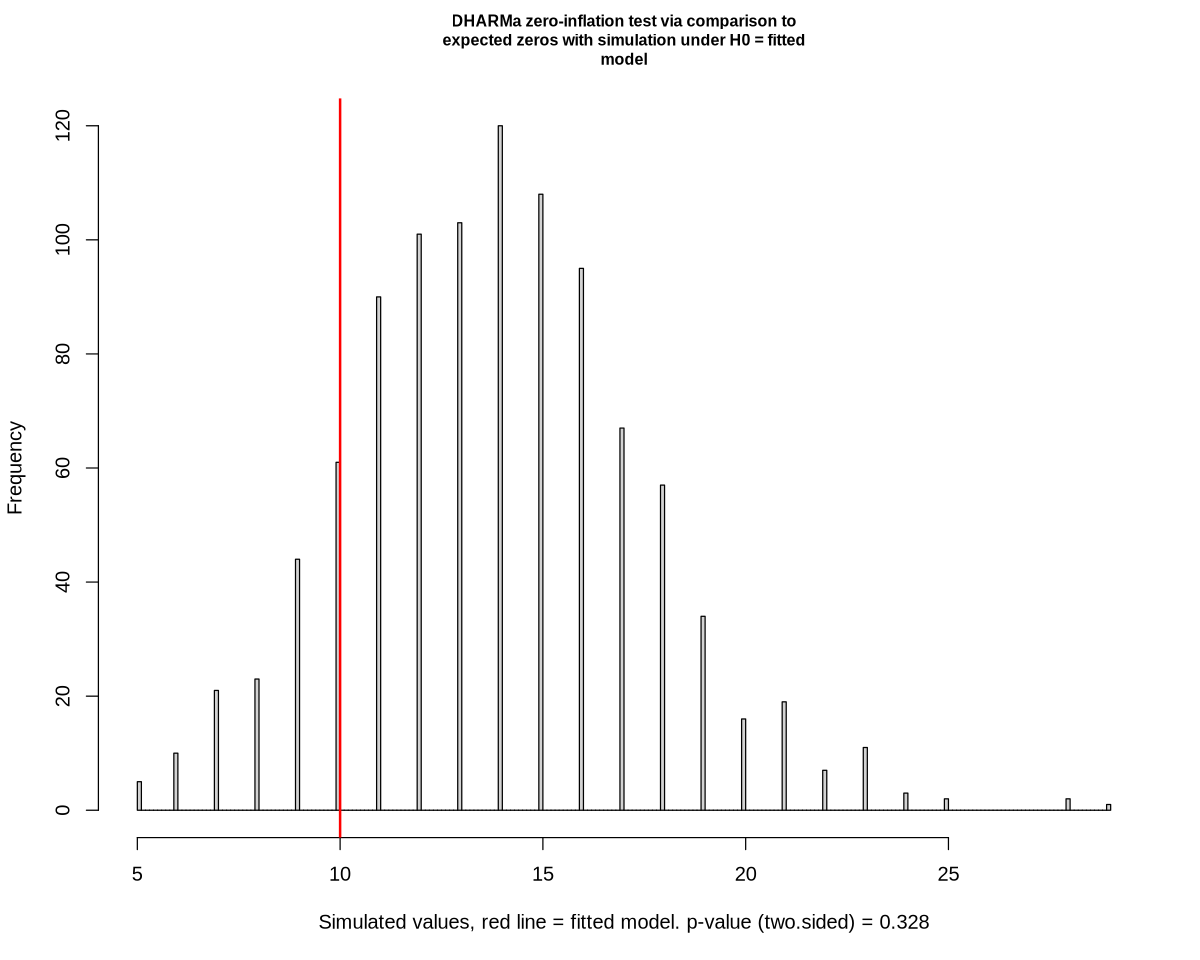

In [23]:
testZeroInflation(result)

### 2.3. Selected model for Transect

In [24]:
model_1 <- model_negative_binomial
summary(model_1)

 Family: nbinom2  ( log )
Formula:          Richness ~ Transect
Data: richness_df

      AIC       BIC    logLik -2*log(L)  df.resid 
    761.1     770.8    -377.6     755.1       186 


Dispersion parameter for nbinom2 family (): 11.7 

Conditional model:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept)  1.11241    0.06567  16.939   <2e-16 ***
TransectB   -0.06528    0.09489  -0.688    0.491    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

## 3. Richness ~ Transect + Wood.Texture

### 3.1. Poisson model

In [25]:
model_poisson <- glm(
    Richness ~ Transect + Wood.Texture,
    family = poisson(link = "log"),
    data = richness_df
)

#### Model performance summary

In [26]:
summary(model_poisson)


Call:
glm(formula = Richness ~ Transect + Wood.Texture, family = poisson(link = "log"), 
    data = richness_df)

Coefficients:
                     Estimate Std. Error z value Pr(>|z|)    
(Intercept)           1.18140    0.08295  14.243   <2e-16 ***
TransectB            -0.07078    0.08498  -0.833    0.405    
Wood.TextureSoftwood -0.10200    0.08837  -1.154    0.248    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 247.85  on 188  degrees of freedom
Residual deviance: 245.94  on 186  degrees of freedom
AIC: 765.08

Number of Fisher Scoring iterations: 5


#### Check for overdispersion

In [27]:
check_overdispersion(model_poisson)

Overdispersion detected.



# Overdispersion test

       dispersion ratio =   1.267
  Pearson's Chi-Squared = 235.598
                p-value =   0.008


Assessment of the Poisson GLM indicated significant overdispersion (dispersion ratio = 1.267, Pearson's χ² = 235.598, p = 0.008), with **the residual variance approximately 27% greater than expected under the Poisson distribution**.

#### Check for goodness-of-fit

In [28]:
result <- simulateResiduals(
    fittedModel = model_poisson,
    n = 1000
)

#### Figure 8: DHARMa simulated residual diagnostics

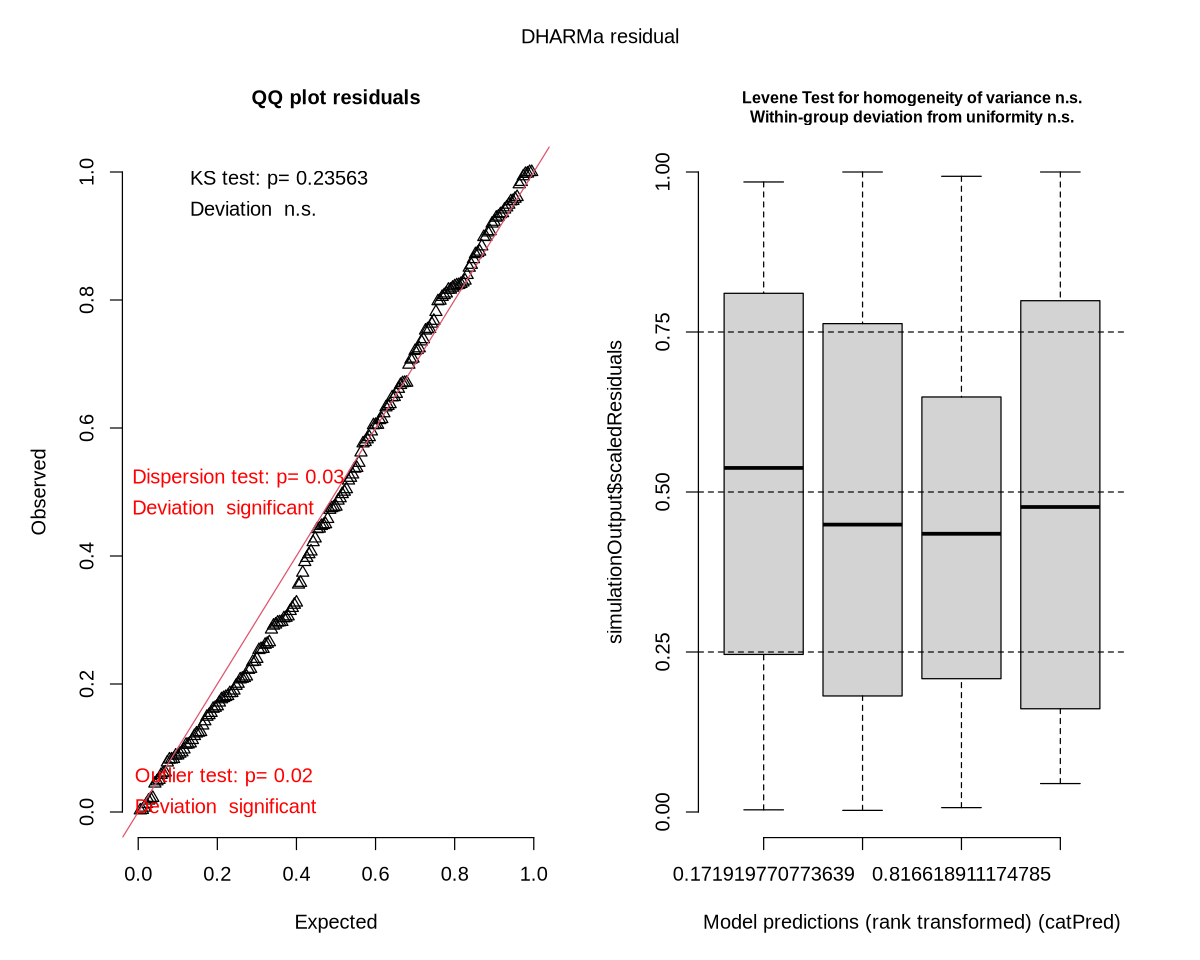

In [29]:
plot(result)

#### Figure 9: DHARMa disperson test result


	DHARMa nonparametric dispersion test via sd of residuals fitted vs.
	simulated

data:  simulationOutput
dispersion = 1.2662, p-value = 0.03
alternative hypothesis: two.sided


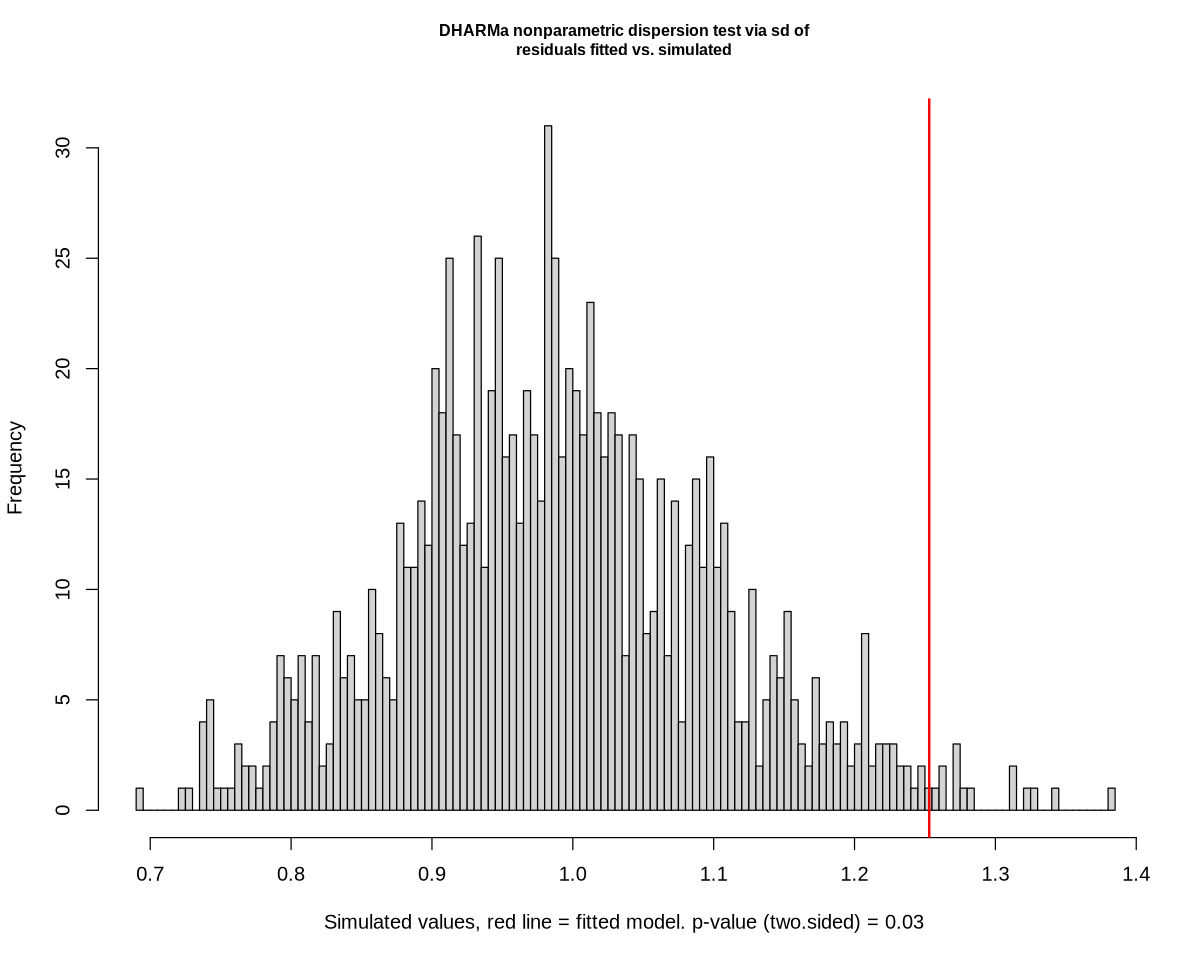

In [30]:
testDispersion(result)

#### Figure 10: DHARMa zero-inflation test result


	DHARMa zero-inflation test via comparison to expected zeros with
	simulation under H0 = fitted model

data:  simulationOutput
ratioObsSim = 0.99167, p-value = 1
alternative hypothesis: two.sided


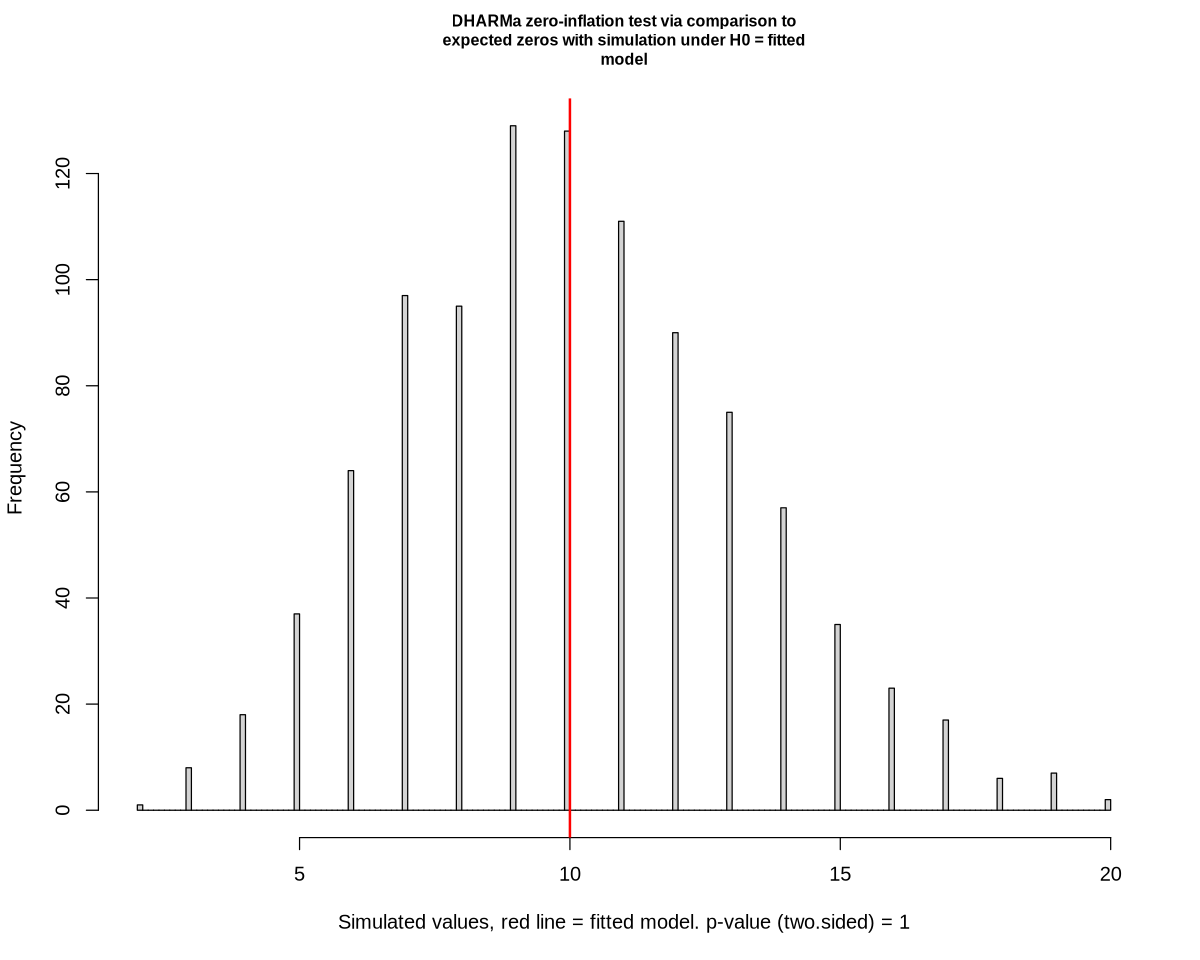

In [31]:
testZeroInflation(result)

### 3.2. Overdispersion detected. Use Negative-binomial model.

In [32]:
model_negative_binomial <- glmmTMB(
    Richness ~
        Transect + Wood.Texture,
    family = nbinom2(link = "log"),
    data = richness_df
)

#### Model performance summary

In [33]:
summary(model_negative_binomial)

 Family: nbinom2  ( log )
Formula:          Richness ~ Transect + Wood.Texture
Data: richness_df

      AIC       BIC    logLik -2*log(L)  df.resid 
    762.1     775.0    -377.0     754.1       185 


Dispersion parameter for nbinom2 family (): 12.1 

Conditional model:
                     Estimate Std. Error z value Pr(>|z|)    
(Intercept)           1.18061    0.09286  12.714   <2e-16 ***
TransectB            -0.06999    0.09474  -0.739    0.460    
Wood.TextureSoftwood -0.10138    0.09882  -1.026    0.305    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

#### Check for overdispersion

In [34]:
check_overdispersion(model_negative_binomial)

No overdispersion detected.



# Overdispersion test (using simulated residuals)

 dispersion ratio = 1.020
          p-value = 0.824


No significant overdispersion was detected (dispersion ratio = 1.020, p = 0.824). **The dispersion ratio was close to 1 (at 1.02), indicating that the variance in sample-level species richness was adequately represented by the fitted model.**

#### Check for goodness-of-fit

In [35]:
result <- simulateResiduals(
    fittedModel = model_negative_binomial,
    n = 1000
)

#### Figure 11: DHARMa simulated residual diagnostics

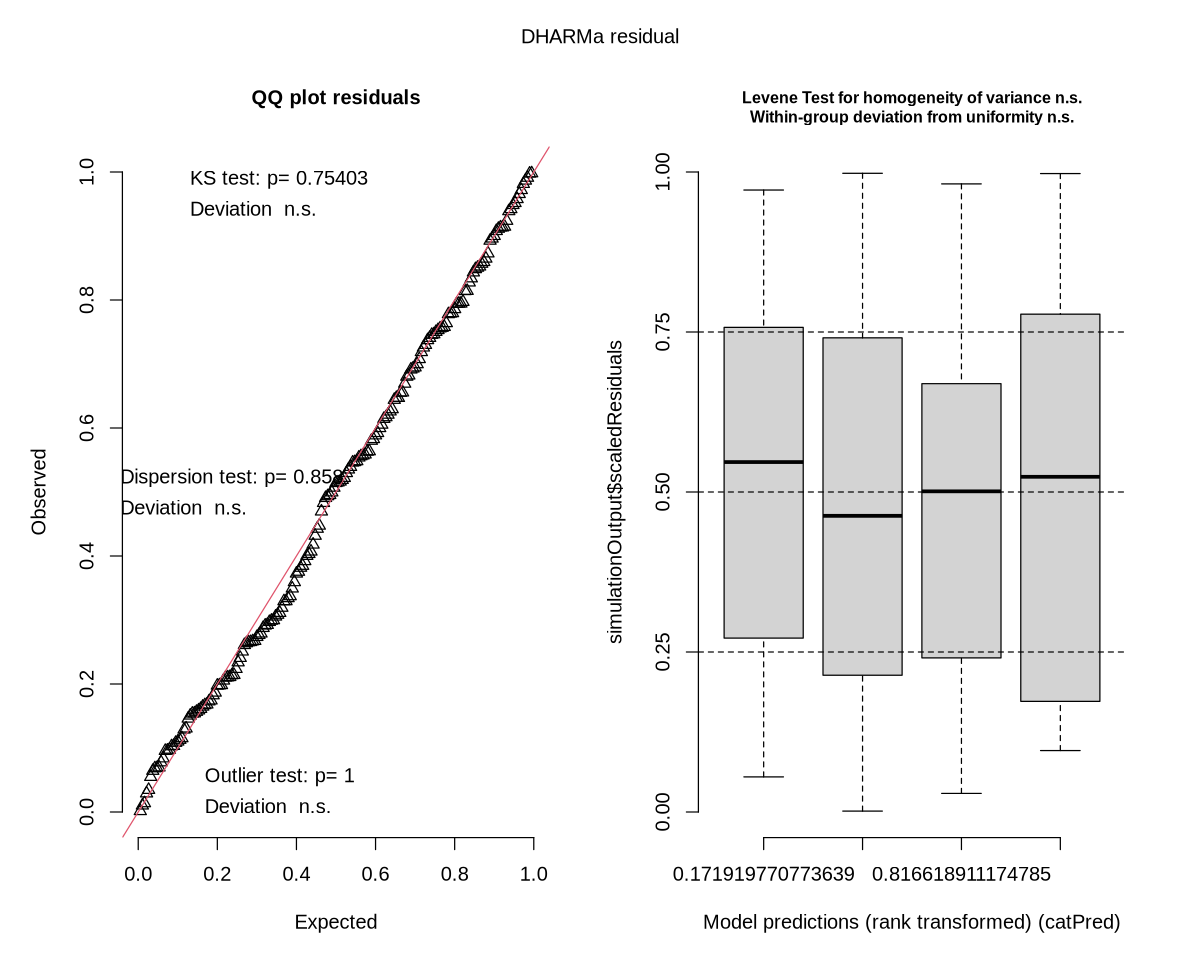

In [36]:
plot(result)

#### Figure 12: DHARMa disperson test result


	DHARMa nonparametric dispersion test via sd of residuals fitted vs.
	simulated

data:  simulationOutput
dispersion = 1.0127, p-value = 0.858
alternative hypothesis: two.sided


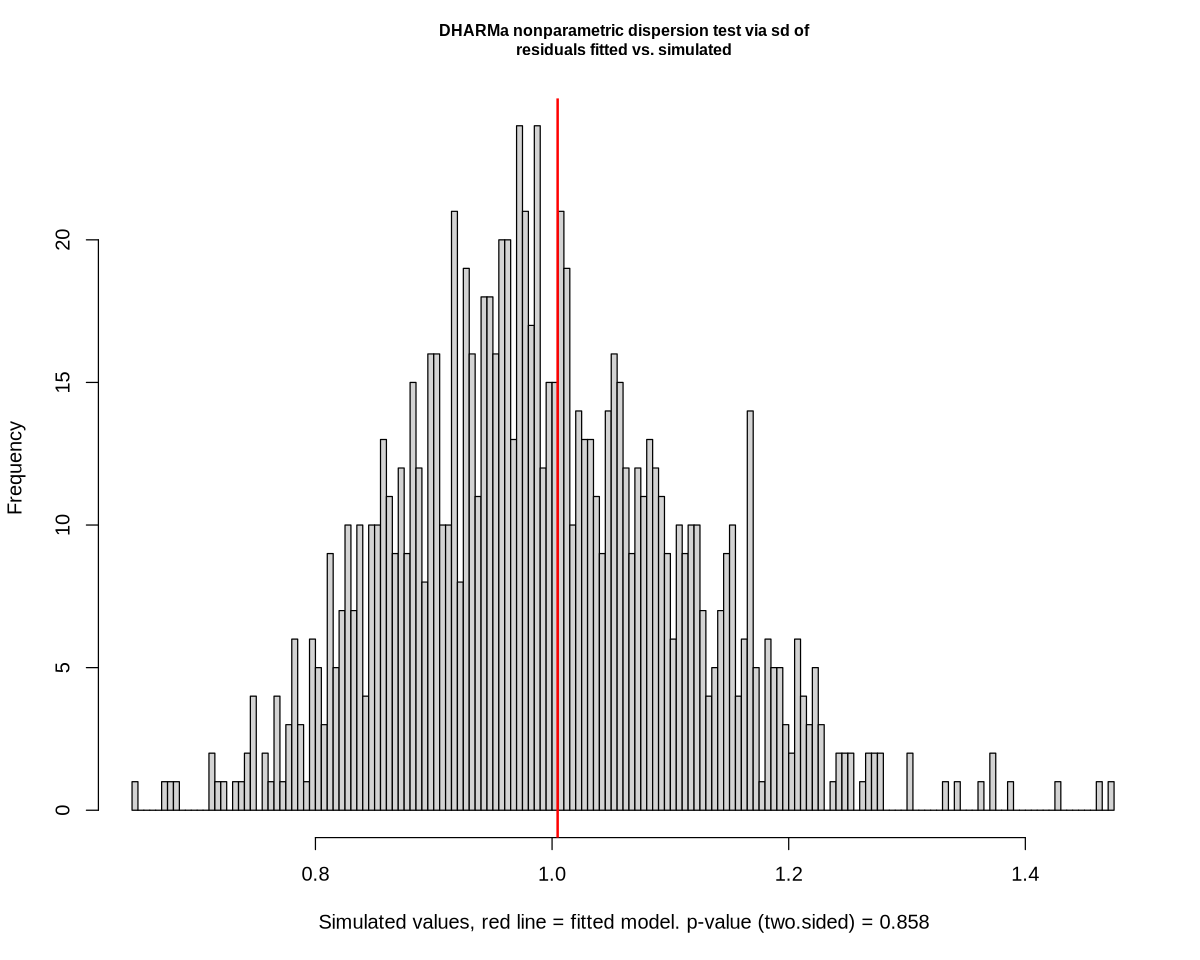

In [37]:
testDispersion(result)

#### Figure 13: DHARMa zero-inflation test result


	DHARMa zero-inflation test via comparison to expected zeros with
	simulation under H0 = fitted model

data:  simulationOutput
ratioObsSim = 0.717, p-value = 0.304
alternative hypothesis: two.sided


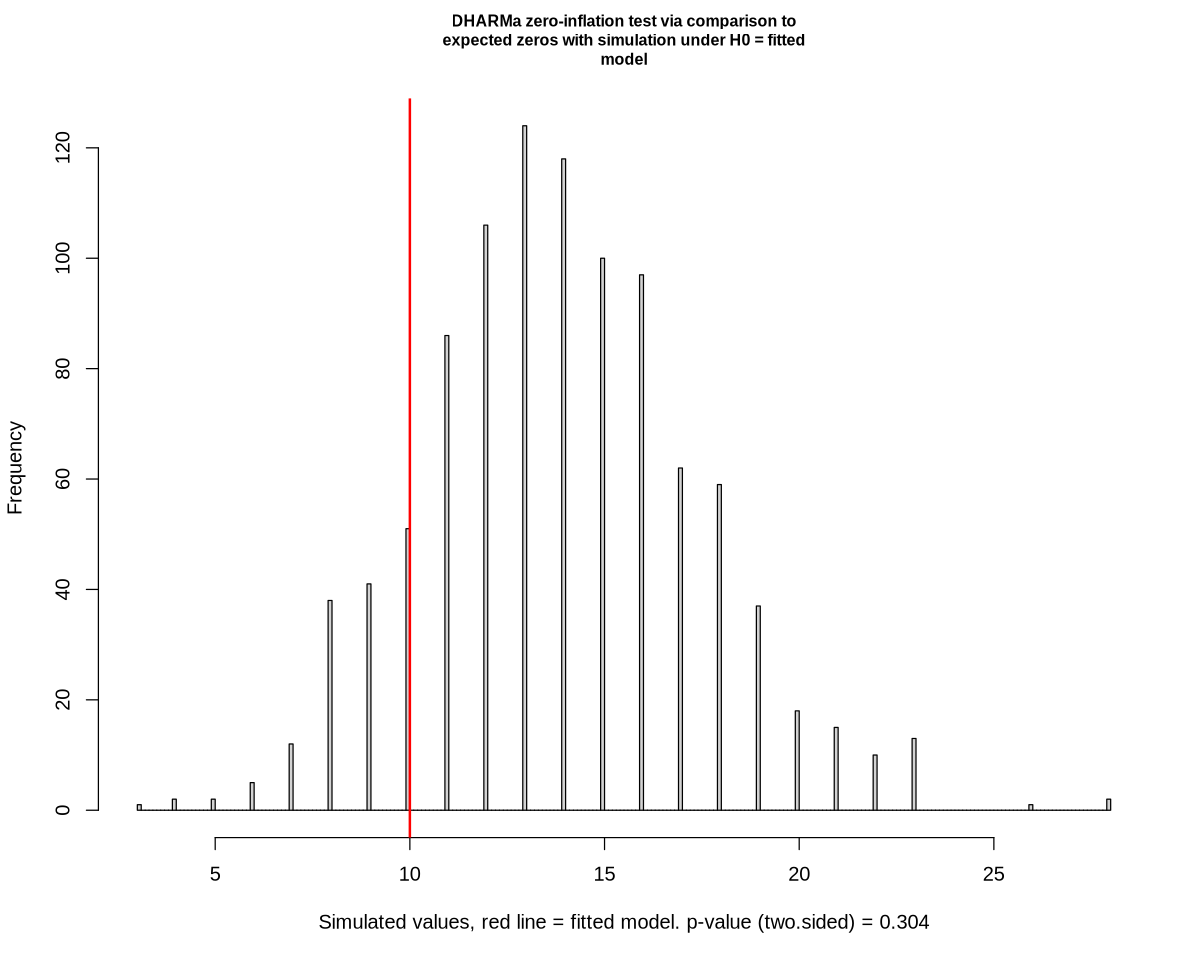

In [38]:
testZeroInflation(result)

### 3.3. Selected model for Transect + Wood.Texture

In [39]:
model_2 <- model_negative_binomial
summary(model_2)

 Family: nbinom2  ( log )
Formula:          Richness ~ Transect + Wood.Texture
Data: richness_df

      AIC       BIC    logLik -2*log(L)  df.resid 
    762.1     775.0    -377.0     754.1       185 


Dispersion parameter for nbinom2 family (): 12.1 

Conditional model:
                     Estimate Std. Error z value Pr(>|z|)    
(Intercept)           1.18061    0.09286  12.714   <2e-16 ***
TransectB            -0.06999    0.09474  -0.739    0.460    
Wood.TextureSoftwood -0.10138    0.09882  -1.026    0.305    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

## 4. Richness ~ Transect + Wood.Type

### 4.1. Poisson Model

In [40]:
model_poisson <- glm(
    Richness ~ Transect + Wood.Type,
    family = poisson(link = "log"),
    data = richness_df
)

#### Model performance summary

In [41]:
summary(model_poisson)


Call:
glm(formula = Richness ~ Transect + Wood.Type, family = poisson(link = "log"), 
    data = richness_df)

Coefficients:
                Estimate Std. Error z value Pr(>|z|)    
(Intercept)      1.18185    0.08294  14.249   <2e-16 ***
TransectB       -0.07167    0.08500  -0.843    0.399    
Wood.TypePine   -0.07556    0.10168  -0.743    0.457    
Wood.TypeSpruce -0.13057    0.10455  -1.249    0.212    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 247.85  on 188  degrees of freedom
Residual deviance: 245.67  on 185  degrees of freedom
AIC: 766.81

Number of Fisher Scoring iterations: 5


#### Check for overdispersion

In [42]:
check_overdispersion(model_poisson)

Overdispersion detected.



# Overdispersion test

       dispersion ratio =   1.274
  Pearson's Chi-Squared = 235.674
                p-value =   0.007


Assessment of the Poisson GLM indicated significant overdispersion (dispersion ratio = 1.274, Pearson's χ² = 235.674, p = 0.007), with **the residual variance approximately 27% greater than expected under the Poisson distribution**.

#### Check for goodness-of-fit

In [43]:
result <- simulateResiduals(
    fittedModel = model_poisson,
    n = 1000
)

#### Figure 14: DHARMa simulated residual diagnostics

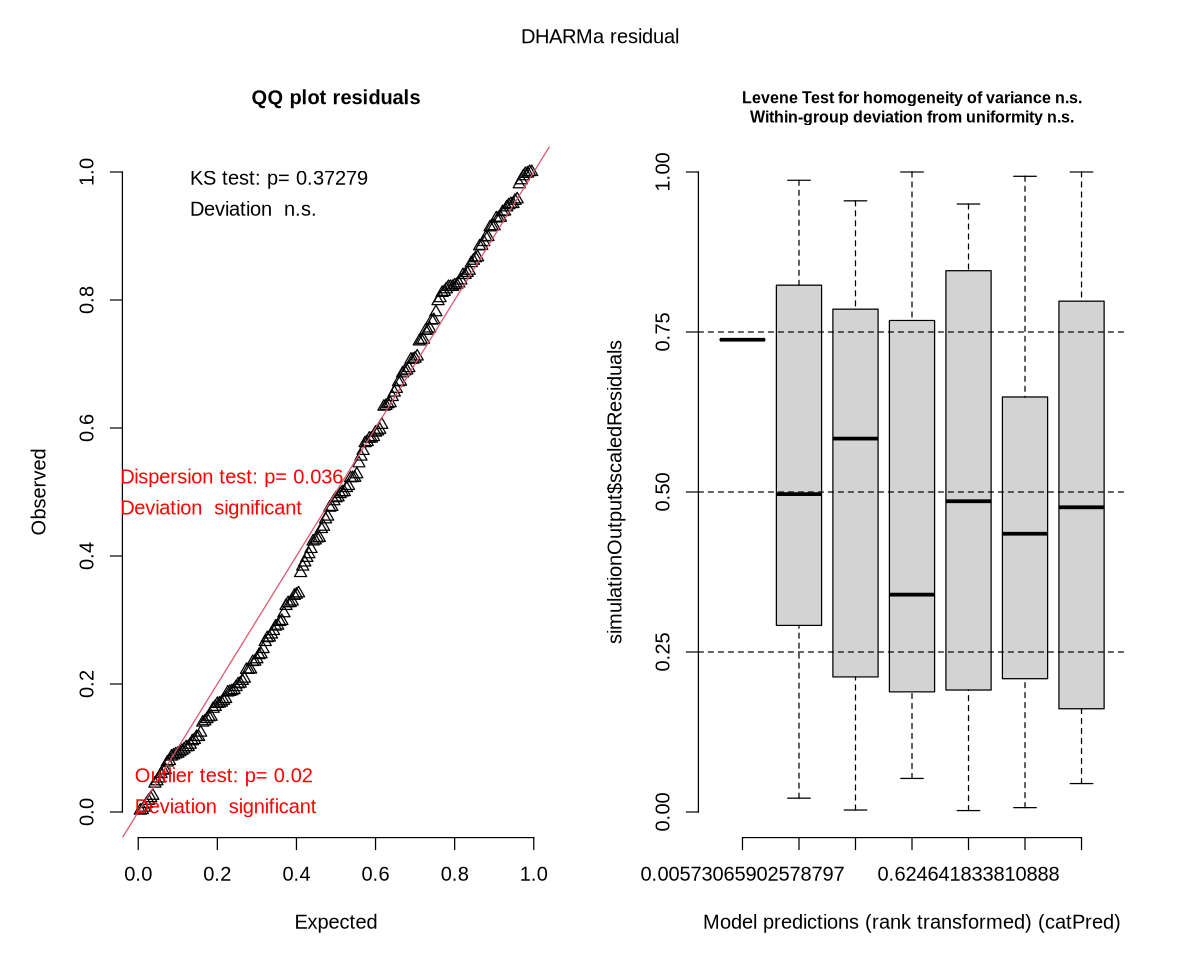

In [44]:
plot(result)

#### Figure 15: DHARMa disperson test result


	DHARMa nonparametric dispersion test via sd of residuals fitted vs.
	simulated

data:  simulationOutput
dispersion = 1.2636, p-value = 0.036
alternative hypothesis: two.sided


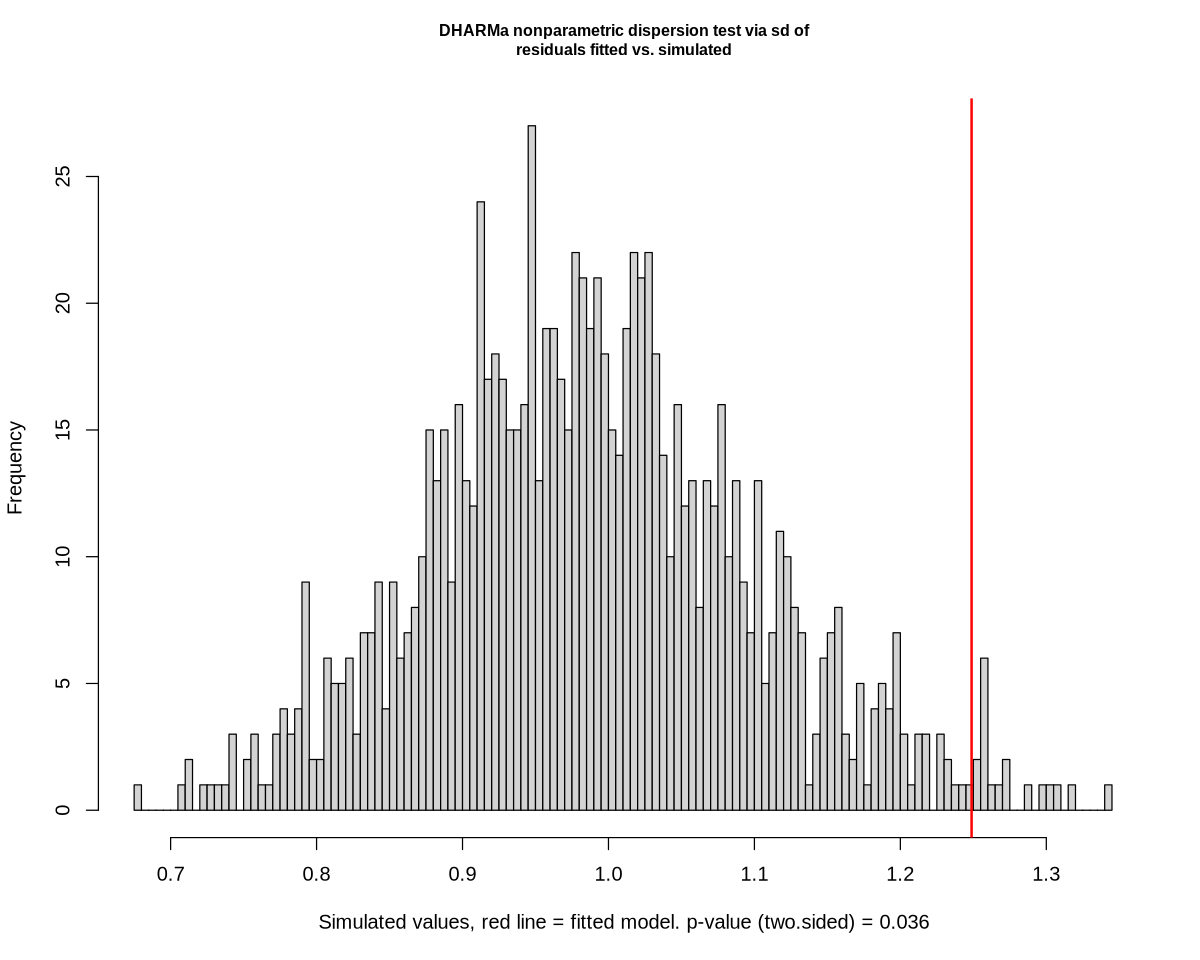

In [45]:
testDispersion(result)

#### Figure 16: DHARMa zero-inflation test result


	DHARMa zero-inflation test via comparison to expected zeros with
	simulation under H0 = fitted model

data:  simulationOutput
ratioObsSim = 0.98844, p-value = 1
alternative hypothesis: two.sided


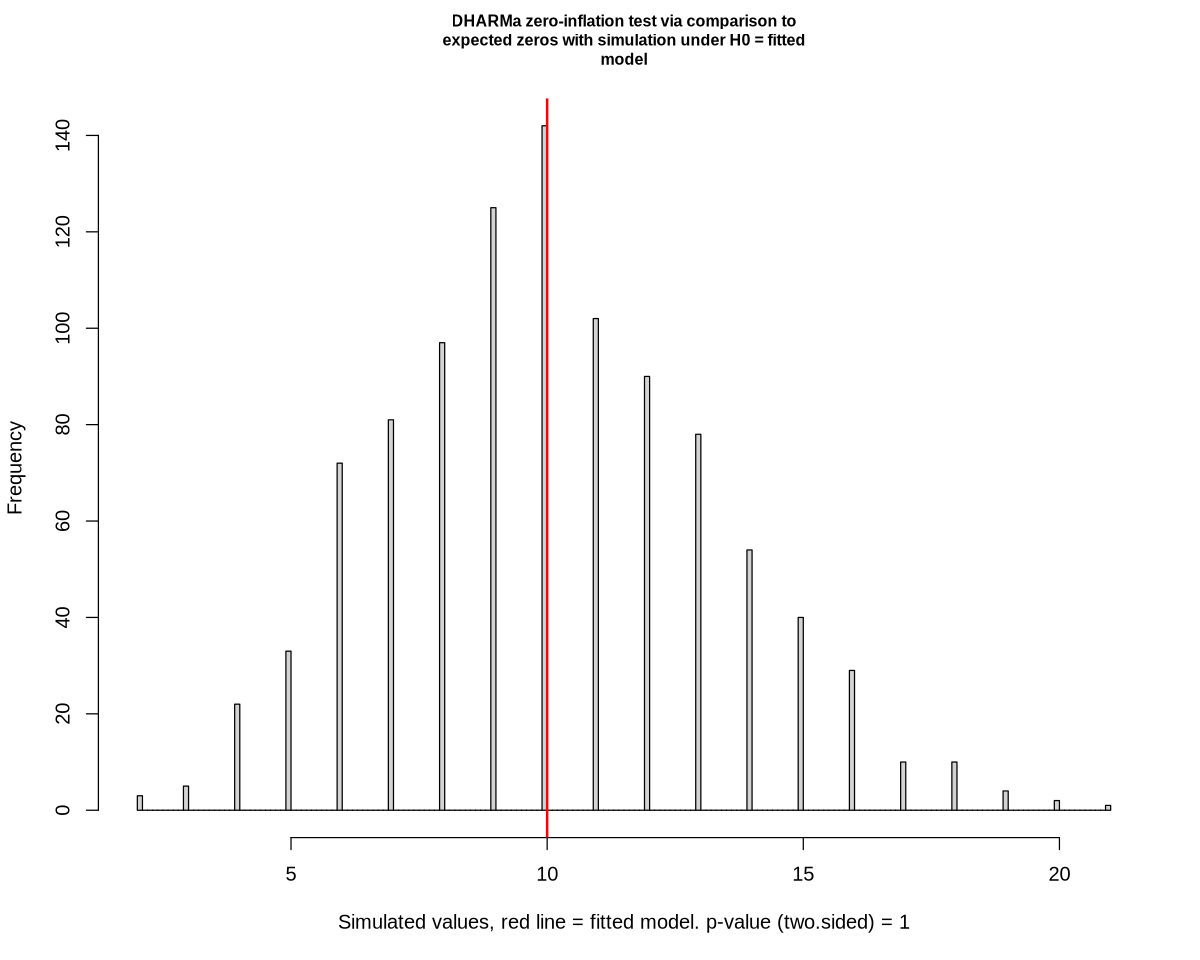

In [46]:
testZeroInflation(result)

### 4.2. Overdispersion detected. Use Negative-binomial model.

In [47]:
model_negative_binomial <- glmmTMB(
    Richness ~
        Transect + Wood.Type,
    family = nbinom2(link = "log"),
    data = richness_df
)

#### Model performance summary

In [48]:
summary(model_negative_binomial)

 Family: nbinom2  ( log )
Formula:          Richness ~ Transect + Wood.Type
Data: richness_df

      AIC       BIC    logLik -2*log(L)  df.resid 
    763.9     780.1    -376.9     753.9       184 


Dispersion parameter for nbinom2 family (): 12.2 

Conditional model:
                Estimate Std. Error z value Pr(>|z|)    
(Intercept)      1.18108    0.09280  12.727   <2e-16 ***
TransectB       -0.07090    0.09471  -0.749    0.454    
Wood.TypePine   -0.07494    0.11363  -0.660    0.510    
Wood.TypeSpruce -0.12995    0.11648  -1.116    0.265    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

#### Check for overdispersion

In [49]:
check_overdispersion(model_negative_binomial)

No overdispersion detected.



# Overdispersion test (using simulated residuals)

 dispersion ratio = 1.021
          p-value = 0.856


No significant overdispersion was detected (dispersion ratio = 1.021, p = 0.856). **The dispersion ratio was close to 1 (at 1.02), indicating that the variance in sample-level species richness was adequately represented by the fitted model.**

#### Check for goodness-of-fit

#### Figure 17: DHARMa simulated residual diagnostics

In [50]:
result <- simulateResiduals(
    fittedModel = model_negative_binomial,
    n = 1000
)

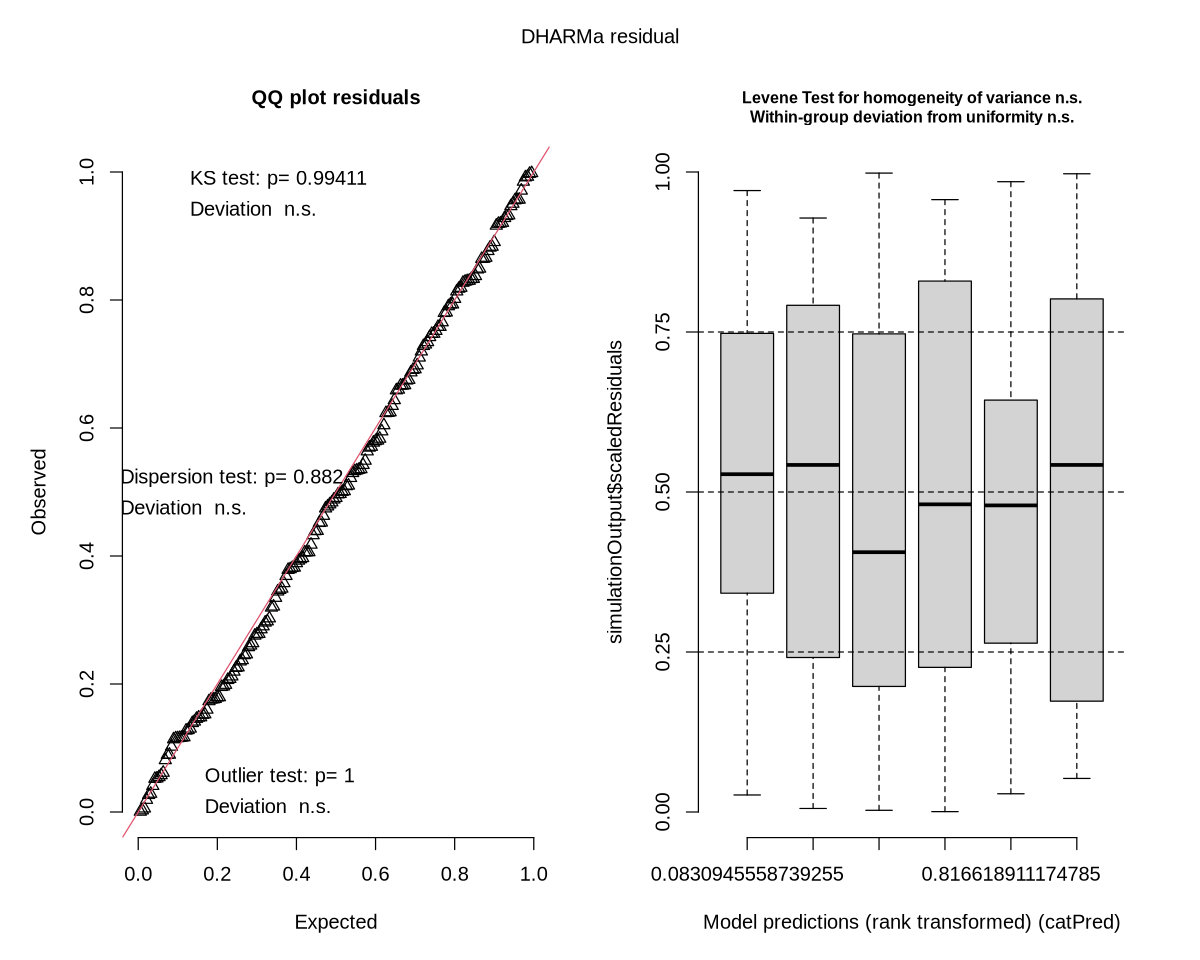

In [51]:
plot(result)

#### Figure 18: DHARMa disperson test result


	DHARMa nonparametric dispersion test via sd of residuals fitted vs.
	simulated

data:  simulationOutput
dispersion = 1.0128, p-value = 0.882
alternative hypothesis: two.sided


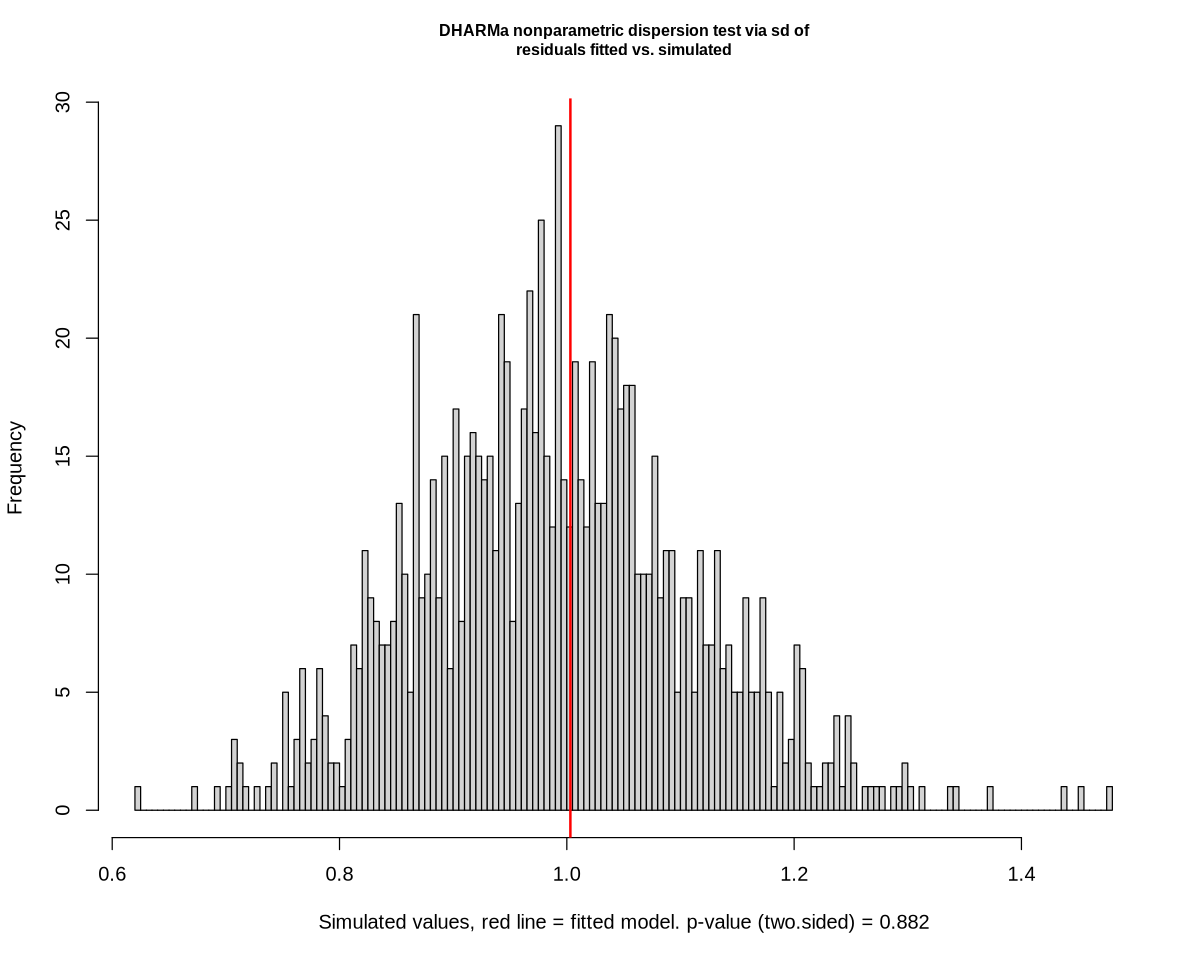

In [52]:
testDispersion(result)

#### Figure 19: DHARMa zero-inflation test result


	DHARMa zero-inflation test via comparison to expected zeros with
	simulation under H0 = fitted model

data:  simulationOutput
ratioObsSim = 0.71551, p-value = 0.334
alternative hypothesis: two.sided


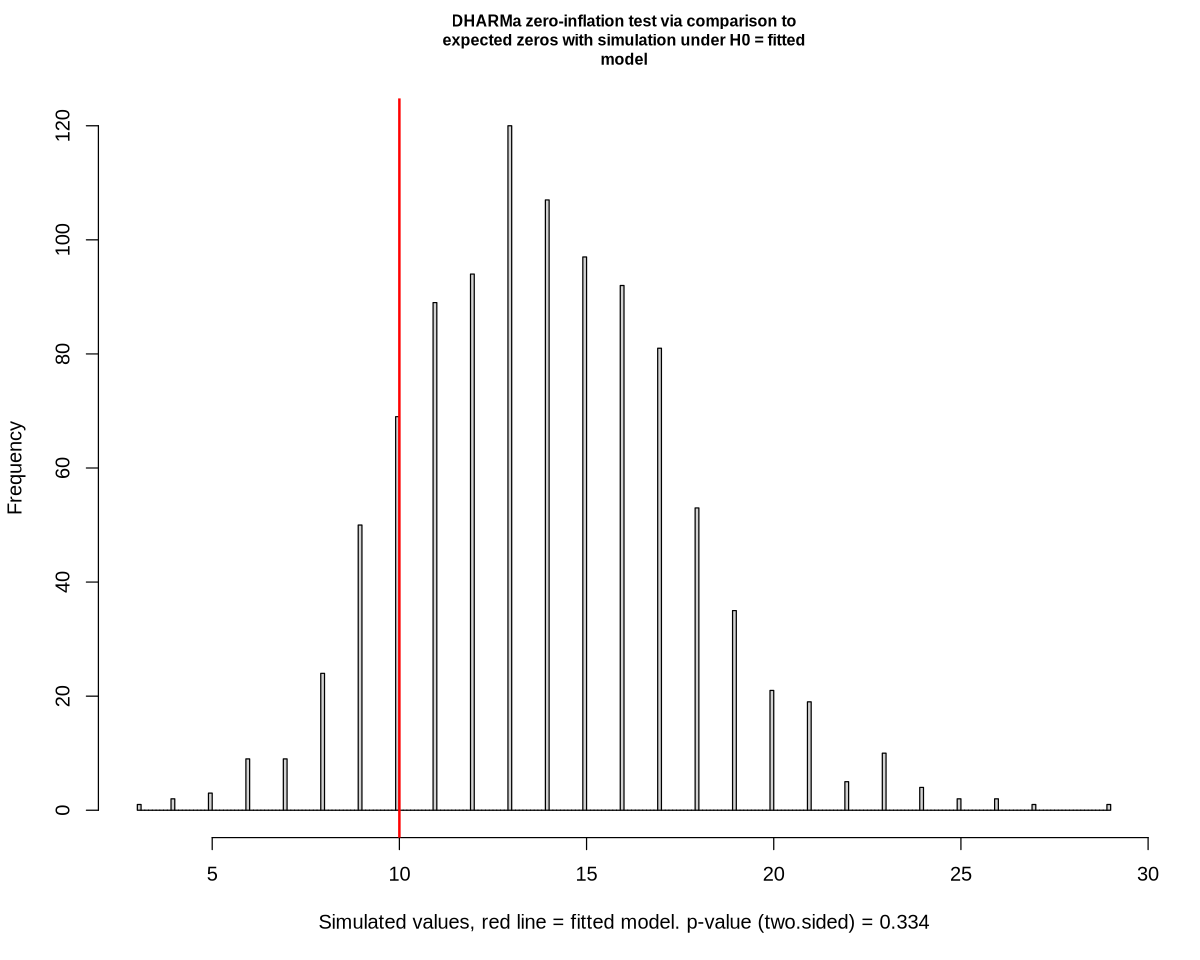

In [53]:
testZeroInflation(result)

### 4.3. Selected model for Transect + Wood.Type

In [54]:
model_3 <- model_negative_binomial
summary(model_3)

 Family: nbinom2  ( log )
Formula:          Richness ~ Transect + Wood.Type
Data: richness_df

      AIC       BIC    logLik -2*log(L)  df.resid 
    763.9     780.1    -376.9     753.9       184 


Dispersion parameter for nbinom2 family (): 12.2 

Conditional model:
                Estimate Std. Error z value Pr(>|z|)    
(Intercept)      1.18108    0.09280  12.727   <2e-16 ***
TransectB       -0.07090    0.09471  -0.749    0.454    
Wood.TypePine   -0.07494    0.11363  -0.660    0.510    
Wood.TypeSpruce -0.12995    0.11648  -1.116    0.265    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

## 5. Model comparison
Using likelihood-ratio tests to compare increasingly complex GLMs for sample-level species richness. 

In [55]:
anova_table <- anova(
    model_1, # Transect
    model_2, # Transect + Wood.Texture
    model_3, # Transect + Wood.Type
    test = "Chisq"
)

#### Table 2: Comparison of generalized linear models for sample-level fungal richness.

In [56]:
caption_text <- paste0(
    "Table 2. Comparison of generalized linear models for sample-level fungal richness. ",
    "Candidate models were compared using AIC, BIC, log-likelihood, deviance, and ",
    "likelihood-ratio tests (χ²). Lower AIC and BIC values indicate better relative model ",
    "support after accounting for model complexity."
)

table2 <- anova_table %>%
    rownames_to_column(var = "Model") %>%
    mutate(
        Model = recode(
            Model,
            "model_1" = "Model 1: Transect",
            "model_2" = "Model 2: Transect + Wood texture",
            "model_3" = "Model 3: Transect + Wood type"
        )
    ) %>%
    gt(rowname_col = "Model") %>%
    tab_style(
        style = cell_text(align = "left"),
        locations = cells_stub()
    ) %>%
    cols_align(
        align = "left",
        columns = "Model"
    ) %>%
    cols_label(
        Df = md("**Model df**"),
        AIC = md("**AIC**"),
        BIC = md("**BIC**"),
        logLik = md("**Log-likelihood**"),
        deviance = md("**Deviance**"),
        Chisq = md("**χ²**"),
        "Chi Df" = md("**Δdf**"),
        "Pr(>Chisq)" = md("**p-value**"),
    ) %>%
    fmt_number(
        columns = where(is.numeric),
        decimals = 2
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [57]:
table2 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

"Chisq)"" class=""gt_row gt_right"" style=""border-style: none; padding-top: 8px; padding-bottom: 8px; padding-left: 5px; padding-right: 5px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: middle; overflow-x: hidden; text-align: right; font-variant-numeric: tabular-nums;"" valign=""middle"" align=""right"">NA"
"Chisq)"" class=""gt_row gt_right"" style=""border-style: none; padding-top: 8px; padding-bottom: 8px; padding-left: 5px; padding-right: 5px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: middle; overflow-x: hidden; text-align: right; font-variant-numeric: tabular-nums;"" valign=""middle"" align=""right"">0.31"
"Chisq)"" class=""gt_row gt_right"" style=""border-style: none; padding-top: 8px; padding-bottom: 8px; padding-left: 5px; padding-right: 5px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: middle; overflow-x: hidden; text-align: right; font-variant-numeric: tabular-nums;"" valign=""middle"" align=""right"">0.64"


The Transect-only model (`Richness ~ Transect`) provided the most parsimonious fit to the data, with the lowest AIC (761.12) and BIC (770.84). Adding Wood Texture did not significantly improve model fit relative to the Transect-only model (χ² = 1.04, df = 1, *p* = 0.307), and further distinguishing samples by Wood Type did not improve fit relative to the Wood Texture model (χ² = 0.22, df = 1, *p* = 0.641). 

Although model deviance decreased slightly with the addition of these predictors, the reductions were small and were accompanied by increases in AIC and BIC, indicating that the additional model complexity was not supported by a corresponding improvement in explanatory performance.

Based on these results, the Transect-only model was retained for subsequent estimation and interpretation of sample-level species richness.

## 6. Predicted sample-level richness

### 6.1. Selected model: Negative-binomial GLM with Transect as a predictor

In [58]:
selected_model <- model_1
summary(selected_model)

 Family: nbinom2  ( log )
Formula:          Richness ~ Transect
Data: richness_df

      AIC       BIC    logLik -2*log(L)  df.resid 
    761.1     770.8    -377.6     755.1       186 


Dispersion parameter for nbinom2 family (): 11.7 

Conditional model:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept)  1.11241    0.06567  16.939   <2e-16 ***
TransectB   -0.06528    0.09489  -0.688    0.491    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

### 6.2. Predicted richness

Model-estimated richness values for Transects A and B are presented in Table 3 and visualized in Figure 20. Predicted richness was slightly higher in Transect A, with an estimated 3.04 species per sample (95% CI: 2.67–3.46), than in Transect B, with an estimated 2.85 species per sample (95% CI: 2.49–3.26). The corresponding confidence intervals overlapped substantially.

In [59]:
richness_est <- emmeans(
    selected_model,
    ~ Transect,
    type = "response"
)

In [60]:
richness_est_df <- as.data.frame(richness_est)

#### Table 3: Generalized linear model estimates of sample-level fungal species richness for Transects A and B.

In [61]:
caption_text <- paste0(
    "Table 3. Generalized linear model estimates of sample-level fungal species richness ",
    "for Transects A and B. Estimated richness values are presented on the response scale ",
    "with standard errors (SE) and 95% confidence intervals"
)

table3 <- richness_est_df %>%
    mutate(
        response = round(response, 2),
        "95% CI" = paste0(round(asymp.LCL, 2), "-", round(asymp.UCL, 2))
    ) %>%
    select (
        Transect,
        response,
        SE,
        "95% CI",
    ) %>%
    gt() %>% 
    cols_label(
        Transect = md("**Transect**"),
        response = md("**Estimated richness**"),
        SE = md("**Standard error**"),
        "95% CI" = md("**95% CI**")
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    fmt_number(
        columns = c(3, 4),
        decimals = 2
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [62]:
table3 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 3. Generalized linear model estimates of sample-level fungal species richness for Transects A and B. Estimated richness values are presented on the response scale with standard errors (SE) and 95% confidence intervals <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="Transect" align="center" bgcolor="#FFFFFF" valign="bottom"> Transect 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="response" align="center" bgcolor="#FFFFFF" valign="bottom"> Estimated richness 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="SE" align="center" bgcolor="#FFFFFF" valign="bottom"> Standard error 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="a95%-CI" align="center" bgcolor="#FFFFFF" valign="bottom"> 95% CI 
 
 
 
 A 
<td headers="response" class="gt_row gt_right" style="border-style: none; padding-top: 8px; padding-bottom: 8px; padding-left: 5px; padding-right: 5px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-co

#### Figure 20: Predicted Sample-Level Fungal Richness by Transect

In [63]:
title_text = "Predicted Sample-Level Fungal Richness by Transect"
subtitle_text = "GLM-estimated species richness with 95% confidence intervals across Transects A, B, and C"
caption_text = paste0(
    "Figure 20. Predicted sample-level species richness across Transects A, B, and C. ",
    "Points represent expected species richness estimated from the generalized linear model, ",
    "and error bars represent 95% confidence intervals. Observed sample-level richness values, ",
    "if shown, are displayed as jittered points to illustrate the underlying distribution of the data."
)

figure20 <- ggplot() +
    geom_jitter(
        data = richness_df,
        aes(
            x = Transect,
            y = Richness
        ),
        width = 0.12,
        alpha = 0.35,
        size = 1.8
    ) +
    geom_point(
        data = richness_est_df,
        aes(
            x = Transect,
            y = response
        ),
        size = 3.5
    ) +
    geom_errorbar(
        data = richness_est_df,
        aes(
            x = Transect,
            ymin = asymp.LCL,
            ymax = asymp.UCL
        ),
        width = 0.12
    ) +
    labs(
        title = title_text,
        subtitle = subtitle_text,
        caption = caption_text,
        x = "Transect",
        y = "Species richness"
    ) +
    make_gginext_labels_and_themes(title_text, subtitle_text, caption_text)

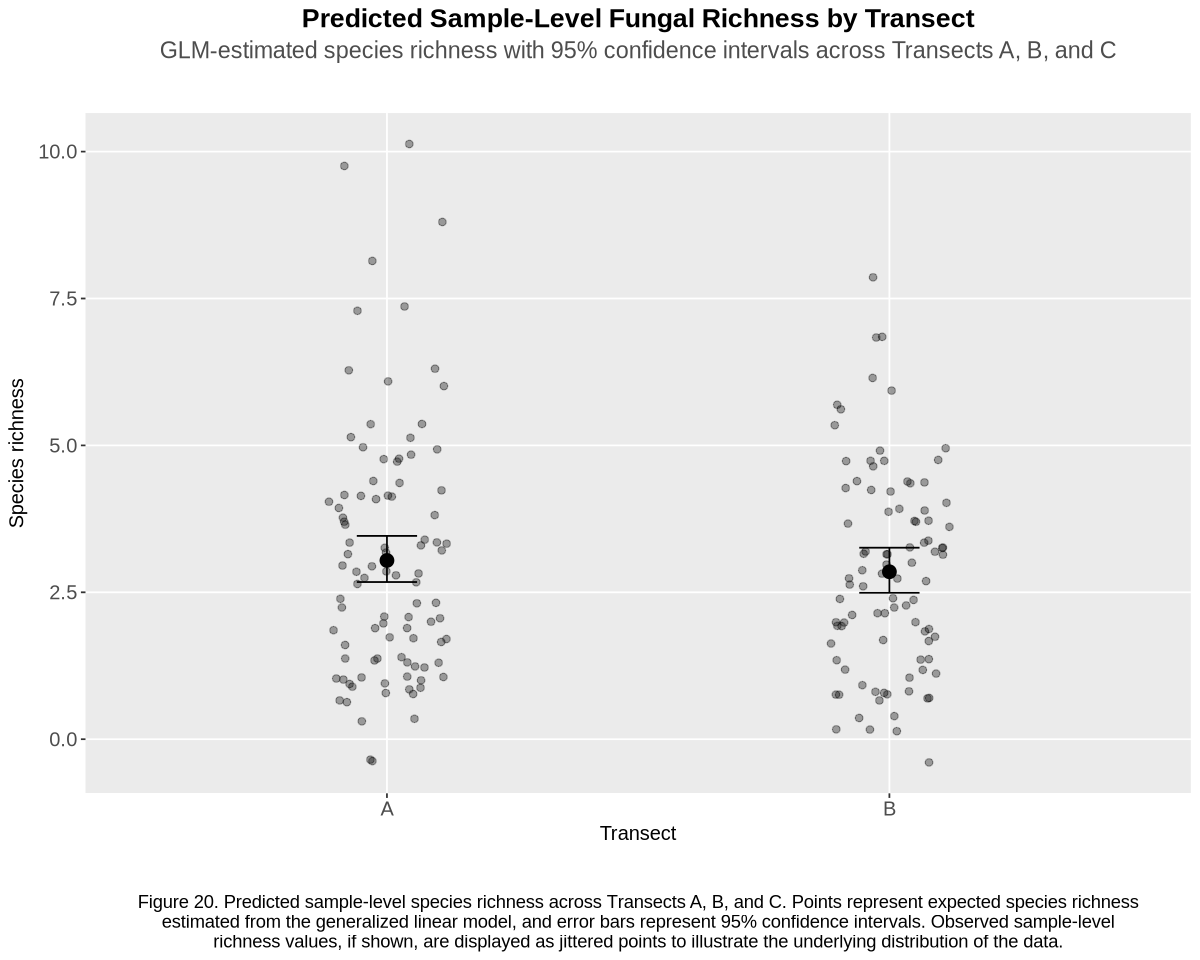

In [64]:
options(repr.plot.width = 10, repr.plot.height = 8)
figure20

The pairwise richness-ratio comparison is presented in Table 4. Expected richness in Transect A was estimated to be 1.07 times that of Transect B, corresponding to approximately 7% greater expected richness in Transect A. This difference was not statistically significant (z = 0.69, p = 0.492), providing no evidence of a significant difference in sample-level fungal richness between Transects A and B.

In [65]:
# compare A and B
compare_result <- as.data.frame(
    pairs(richness_est, type = "response")
)

#### Table 4: Pairwise comparison of GLM-estimated sample-level fungal species richness between Transects A and B.

In [66]:
caption_text <- paste0(
    "Table 4. Pairwise comparison of GLM-estimated sample-level fungal species richness ",
    "between Transects A and B. The richness ratio represents the ratio of expected ",
    "species richness between transects on the response scale. ",
    "A richness ratio of 1 indicates equal expected richness between transects; ",
    "values greater than 1 indicate greater expected richness in the numerator transect. ",
    "Statistical tests were performed on the log scale."
)

table4 <- compare_result %>%
    select(
        contrast,
        ratio,
        SE,
        z.ratio,
        p.value
    ) %>%
    gt() %>% 
    cols_label(
        contrast = md("**Contrast**"),
        ratio = md("**Richness ratio**"),
        SE = md("**Standard error**"),
        z.ratio = md("**z**"),
        p.value = md("**p.value**")
    ) %>%
    cols_align(
        align = "center",
        columns = 1
    ) %>%
    fmt_number(
        columns = where(is.numeric),
        decimals = 2
    ) %>%
    tab_style(
        style = cell_text(align = "center"),
        locations = cells_column_labels(columns = everything())
    ) %>%
    tab_caption(
        caption = md(caption_text)
    ) 

In [67]:
table4 %>%
    as_raw_html(inline_css = TRUE) %>%
    display_html()

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 <!--/html_preserve--> Table 4. Pairwise comparison of GLM-estimated sample-level fungal species richness between Transects A and B. The richness ratio represents the ratio of expected species richness between transects on the response scale. A richness ratio of 1 indicates equal expected richness between transects; values greater than 1 indicate greater expected richness in the numerator transect. Statistical tests were performed on the log scale. <!--html_preserve-->
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" scope="col" id="contrast" align="center" bgcolor="#FFFFFF" valign="bottom"> Contrast 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="ratio" align="center" bgcolor="#FFFFFF" valign="bottom"> Richness ratio 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="SE" align="center" bgcolor="#FFFFFF" valign="bottom"> Standard error 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; font-variant-numeric: tabular-nums; text-align: center;" scope="col" id="z.ratio" align="center" bgcolor="#FFFFFF" valign="bottom"> z 
 <th class="gt_col_heading gt_columns_bottom_border gt_right" rowspan="1" colspan="1" style="border-style: none; color: 

## 7. Adjusted effects on sample-level species richness

In [68]:
# Extract the estimated fixed-effect coefficients for the conditional mean model
coefficients <- fixef(selected_model)$cond
# Exponentitate it becuase the models uses log link
ratio_of_expected_means <- exp(coefficients[2])
ratio_of_expected_means <- 0.936809471135455

markdown_text <- paste0(
    "Therefore, expected richness in transect B is approximately ",
    round(ratio_of_expected_means, 4),
    " times that in transect A or ",
    round((1-ratio_of_expected_means)*100, 2), 
    "% lower")

In [69]:
display_markdown(markdown_text)

Therefore, expected richness in transect B is approximately 0.9368 times that in transect A or 6.32% lower

## Citations

In [70]:
citation("performance")

To cite package ‘performance’ in publications use:

  Lüdecke et al., (2021). performance: An R Package for Assessment,
  Comparison and Testing of Statistical Models. Journal of Open Source
  Software, 6(60), 3139. https://doi.org/10.21105/joss.03139

A BibTeX entry for LaTeX users is

  @Article{,
    title = {{performance}: An {R} Package for Assessment, Comparison and Testing of Statistical Models},
    author = {Daniel Lüdecke and Mattan S. Ben-Shachar and Indrajeet Patil and Philip Waggoner and Dominique Makowski},
    year = {2021},
    journal = {Journal of Open Source Software},
    volume = {6},
    number = {60},
    pages = {3139},
    doi = {10.21105/joss.03139},
  }

In [71]:
citation("DHARMa")

To cite package ‘DHARMa’ in publications use:

  Hartig F (2026). _DHARMa: Residual Diagnostics for Hierarchical
  (Multi-Level / Mixed) Regression Models_.
  doi:10.32614/CRAN.package.DHARMa
  <https://doi.org/10.32614/CRAN.package.DHARMa>, R package version
  0.5.0, <https://CRAN.R-project.org/package=DHARMa>.

A BibTeX entry for LaTeX users is

  @Manual{,
    title = {DHARMa: Residual Diagnostics for Hierarchical (Multi-Level / Mixed)
Regression Models},
    author = {Florian Hartig},
    year = {2026},
    note = {R package version 0.5.0},
    url = {https://CRAN.R-project.org/package=DHARMa},
    doi = {10.32614/CRAN.package.DHARMa},
  }

In [72]:
citation("glmmTMB")

To cite glmmTMB in publications use:

  Mollie E. Brooks, Kasper Kristensen, Koen J. van Benthem, Arni
  Magnusson, Casper W. Berg, Anders Nielsen, Hans J. Skaug, Martin
  Maechler and Benjamin M. Bolker (2017). glmmTMB Balances Speed and
  Flexibility Among Packages for Zero-inflated Generalized Linear Mixed
  Modeling. The R Journal, 9(2), 378-400. doi: 10.32614/RJ-2017-066.

To cite glmmTMB in publications use:

  McGillycuddy M, Warton DI, Popovic G, Bolker BM (2025).
  “Parsimoniously Fitting Large Multivariate Random Effects in
  glmmTMB.” _Journal of Statistical Software_, *112*(1), 1-19.
  doi:10.18637/jss.v112.i01 <https://doi.org/10.18637/jss.v112.i01>.

To see these entries in BibTeX format, use 'print(<citation>,
bibtex=TRUE)', 'toBibtex(.)', or set
'options(citation.bibtex.max=999)'.

In [73]:
citation("emmeans")

To cite package ‘emmeans’ in publications use:

  Lenth R, Piaskowski J (2026). _emmeans: Estimated Marginal Means, aka
  Least-Squares Means_. doi:10.32614/CRAN.package.emmeans
  <https://doi.org/10.32614/CRAN.package.emmeans>, R package version
  2.0.4, <https://CRAN.R-project.org/package=emmeans>.

A BibTeX entry for LaTeX users is

  @Manual{,
    title = {emmeans: Estimated Marginal Means, aka Least-Squares Means},
    author = {Russell V. Lenth and Julia Piaskowski},
    year = {2026},
    note = {R package version 2.0.4},
    url = {https://CRAN.R-project.org/package=emmeans},
    doi = {10.32614/CRAN.package.emmeans},
  }

In [74]:
citation("vegan")

To cite package ‘vegan’ in publications use:

  Oksanen J, Simpson G, Blanchet F, Kindt R, Legendre P, Minchin P,
  O'Hara R, Solymos P, Stevens M, Szoecs E, Wagner H, Bedward M, Bolker
  B, Borcard D, Carvalho G, De Caceres M, Durand S, Evangelista H,
  Hannigan G, Hill M, Lahti L, Martino C, Ouellette M, Ribeiro Cunha E,
  Smith T, Stier A, Ter Braak C, Weedon J (2026). _vegan: Community
  Ecology Package_. doi:10.32614/CRAN.package.vegan
  <https://doi.org/10.32614/CRAN.package.vegan>, R package version
  2.7-5, <https://CRAN.R-project.org/package=vegan>.

A BibTeX entry for LaTeX users is

  @Manual{,
    title = {vegan: Community Ecology Package},
    author = {Jari Oksanen and Gavin L. Simpson and F. Guillaume Blanchet and Roeland Kindt and Pierre Legendre and Peter R. Minchin and R.B. O'Hara and Peter Solymos and M. Henry H. Stevens and Eduard Szoecs and Helene Wagner and Michael Bedward and Ben Bolker and Daniel Borcard and Gustavo Carvalho and Miquel {De Caceres} and Sebastien